In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/BM29_lib.py:282: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel("$q$ [nm$\mathrm{^{-1}}]$", fontsize=25)
/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/BM29_lib.py:537: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  f"$\chi^2_{{\mathrm{{red}}}} = {red_chi2:.3f}$\n"
/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/BM29_lib.py:537: SyntaxWarning: "\m" is an invalid

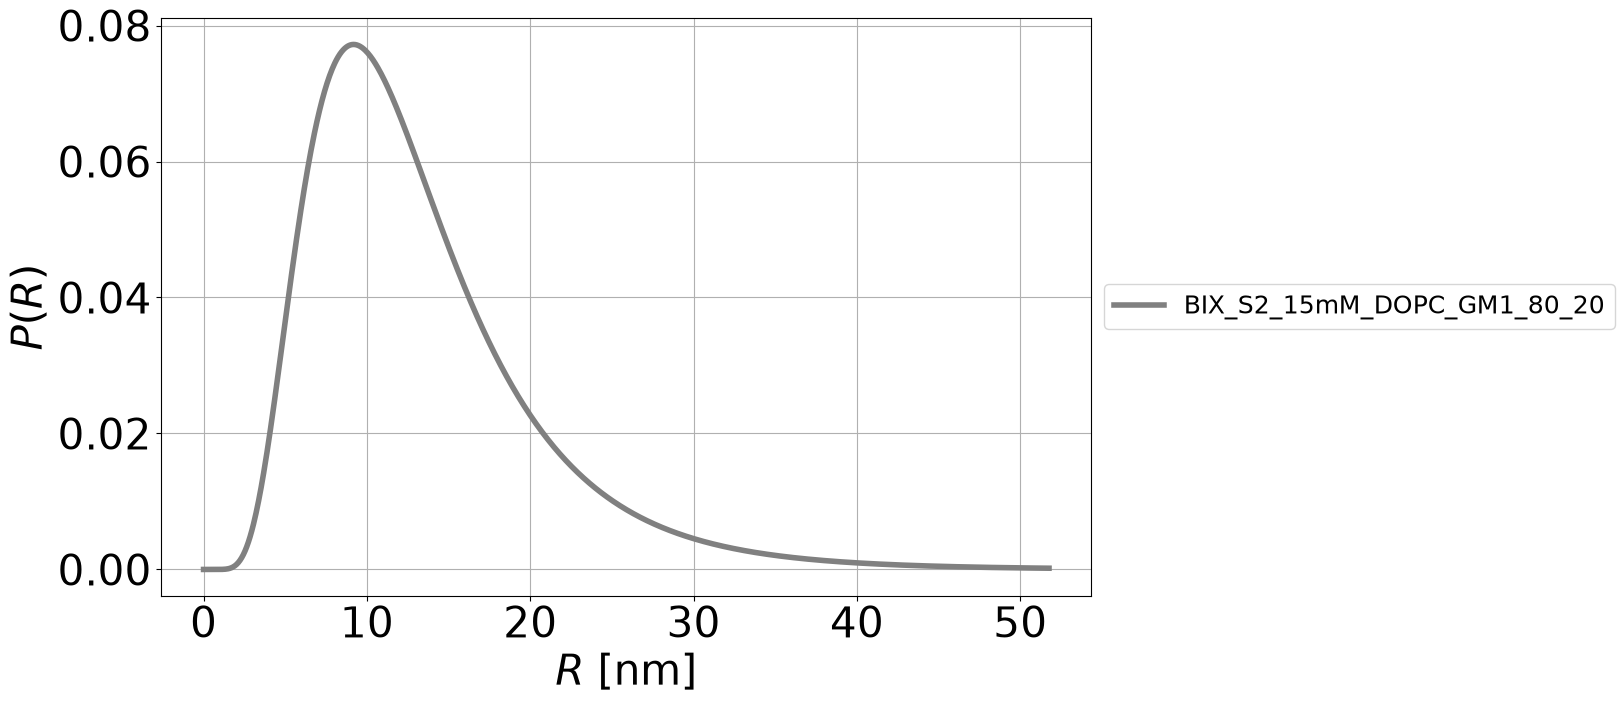

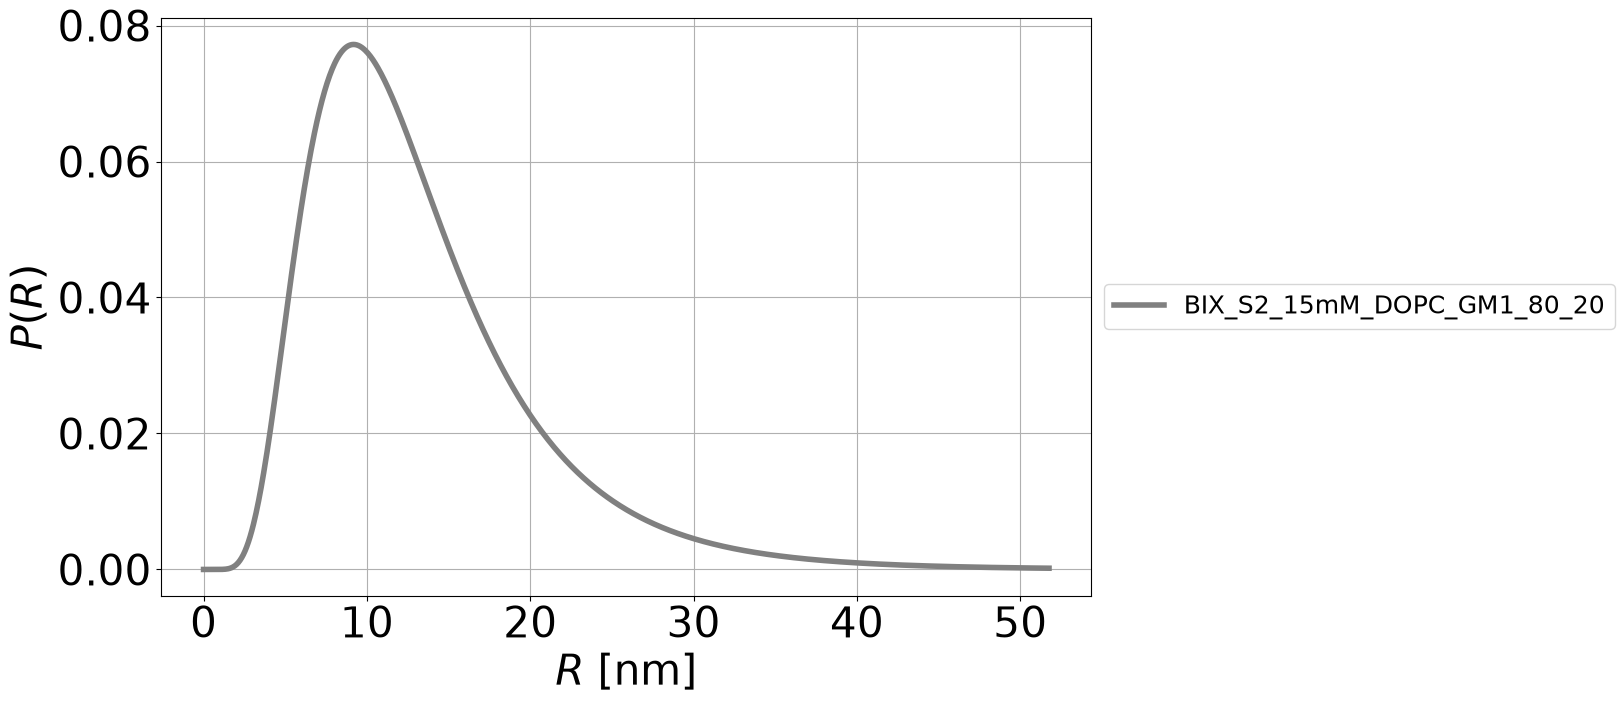

In [2]:
# # ULV_lognormal_sph_asym_TWO_prot_layers
who = ["BIX_S2"]
BM29.EDP_plot_together(who, title="", fit_function="ULV_lognormal_sph_asym_TWO_prot_layers")
BM29.plot_together_lognorm_polydisp(who, fit_function_name="ULV_lognormal_sph_asym_TWO_prot_layers")

In [3]:
# print and look at DOPS fits
PCPS = [
    "BII_S11", #: "15 mM DOPC/DOPS (8/2)",

    "BIX_S15", #: "15 mM DOPC/DOPS (8/2) + 6 μM aSynWT",
    "BIX_S16", #: "15 mM DOPC/DOPS  (8/2) + 9 μM aSynWT",
    "BIX_S17", #: "15 mM DOPC/DOPS (8/2) + 15 μM aSynWT",
    "BIX_S18", #: "15 mM DOPC/DOPS (8/2) + 25 μM aSynWT",
    "BIX_S19", #: "15 mM DOPC/DOPS (8/2) + 50 μM aSynWT",

    # "BVII_S4", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynWT", # bgr sub removed too much of the curve
    "BVII_S5", #: "15 mM DOPC/DOPS (8/2) + 100 μM aSynWT",
    "BVII_S10", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynE61V",
    "BVII_S15", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynA124T",
    "BVII_S20", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynE46K",
]

for sample in PCPS:
    print("sample", sample, "fit:", BM29.best_fits[sample]["ULV_spheric_asym_C4"][1])

sample BII_S11 fit: [16.4, 2.966, 1.594, 0.9678, 0.3711, 0.3601, 0.8142, 1.78, 0.0001319, 0.0004316]
sample BIX_S15 fit: [17.06, 2.762, 1.538, 1.006, 0.3722, 0.3436, 0.8049, 1.778, 0.0001357, 0.0005374]
sample BIX_S16 fit: [17.01, 2.854, 1.528, 1.034, 0.3769, 0.3362, 0.8107, 1.774, 0.0001385, 0.0005207]
sample BIX_S17 fit: [16.97, 3.06, 1.481, 1.052, 0.3759, 0.3049, 0.7662, 1.784, 0.0001407, 0.000602]
sample BIX_S18 fit: [16.58, 4.304, 1.74, 0.8465, 0.3303, 0.3479, 0.751, 1.785, 0.000144, 0.0006345]
sample BIX_S19 fit: [17.2, 5.494, 1.674, 1, 0.3456, 0.2429, 0.6897, 1.801, 0.0001375, 0.0007067]
sample BVII_S5 fit: [18.85, 6.191, 1.6, 1.6, 0.3674, 0.1284, 0.6484, 1.812, 0.0001153, 0.0007696]
sample BVII_S10 fit: [18.84, 6.09, 1.878, 1.2, 0.3127, 0.1546, 0.6235, 1.817, 9.774e-05, 0.0007237]
sample BVII_S15 fit: [15.94, 6.352, 2.087, 0.7394, 0.2934, 0.3227, 0.708, 1.793, 0.0001445, 0.000684]
sample BVII_S20 fit: [16.64, 5.808, 1.814, 0.8462, 0.3247, 0.2835, 0.6929, 1.795, 0.0001526, 0.000

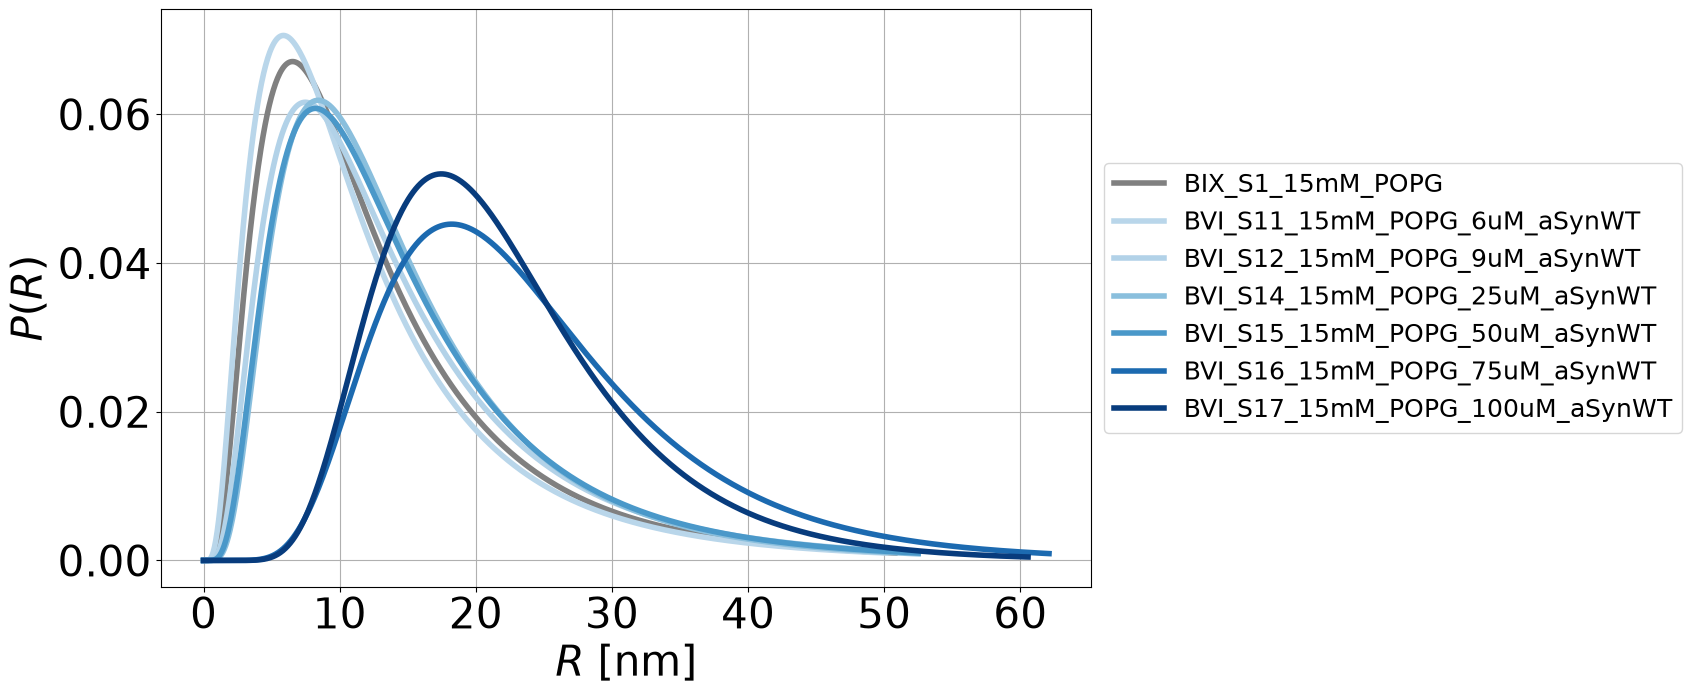

In [8]:
# PLOT POPG LOGNORM POLYDISPERSITY FITS
who = [
    "BIX_S1",
    "BVI_S11",
    "BVI_S12",
        #    "BVI_S13",
    "BVI_S14",
    "BVI_S15",
    "BVI_S16",
    "BVI_S17",
    # "BVI_S18",
    # "BVI_S19",
    # "BVI_S20",
]
g = BM29.plot_together_lognorm_polydisp(who)
# BM29.plot_together(who, "", min_cutoff=0.07)

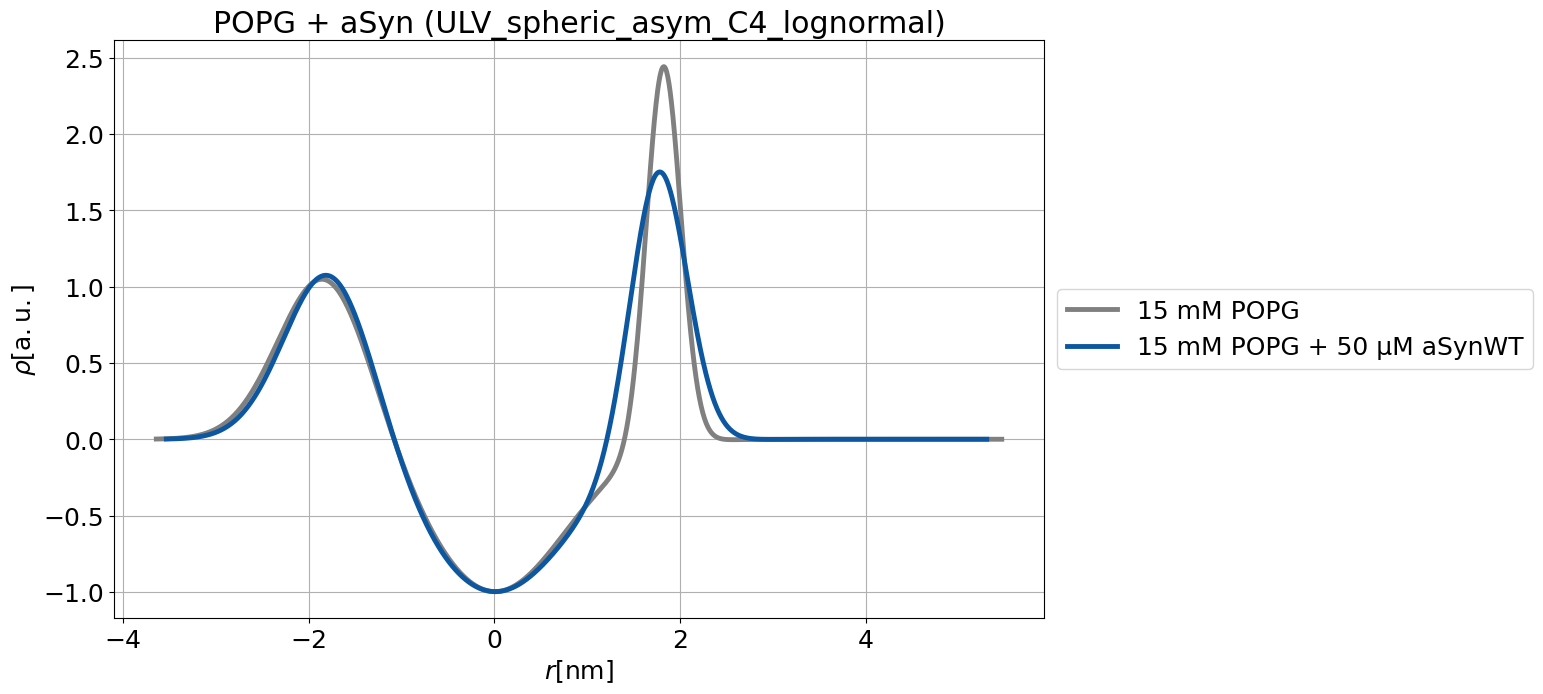

In [10]:
# PLOT EDPs TOGETHER
who = [
    "BIX_S1",
    # "BVI_S11",
    # "BVI_S12",
    # "BVI_S13",
    "BVI_S15",
    # "BVI_S16",
    # "BVI_S17",

    # "BVI_S14",
    # "BVI_S18",
    # "BVI_S19",
    # "BVI_S20",
]

BM29.plot_together(who, "POPG")
fit_function="ULV_spheric_asym_C4_lognormal"
BM29.EDP_plot_together(who, f"POPG + aSyn ({fit_function})", fit_function=fit_function)

# for sample in who:
#     for i, params in BM29.best_fits[sample]["ULV_sph_asym_prot_layer"].items():
#         print(sample, i, params[-3])

In [3]:
best_fits_POPG_aSynWT = {    
    'BVI_S11': {
        'ULV_spheric_asym_C4': { # chi2 80 to 87
            1: [18.97, 9.673, 2.277, 0.9919, 0.2508, 0.486, 0.789, 1.801, 0.000109, 0.0005184],
            2: [18.81, 9.686, 1.156, 1.956, 0.486, 0.2506, 0.7893, 1.801, 0.0001105, 0.0005189],
            3: [19.88, 8.5, 1.4, 1.4, 0.4005, 0.3435, 0.7784, 1.807, 0.0001053, 0.0006622],
            4: [19.39, 8.391, 1.874, 1.2, 0.335, 0.4504, 0.8967, 1.783, 0.0001042, 0.0006221],
        },
        "ULV_spheric_asym_C4_lognormal": {
            1: [10.07, 0.7351, 1.207, 1.808, 0.4677, 0.2614, 0.7746, 1.807, 3.827e-07, 0.0005554], # chi2 = 74
        },
        'ULV_sph_asym_prot_layer': { # all quite good chi2 between 69 and 85
            1: [15.7, 10, 1.129, 1.892, 0.4573, 0.2494, 0.7428, 1.815, 4.999, 1.192, 0.01155, 3.007e-07, 0.0005299], # PREMIUM chi2 = 69
            2: [18.44, 10, 1.534, 1.76, 0.4819, 0.3651, 1.11, 1.768, 4.915, 1.167, 0.008602, 2.035e-07, 0.000613], # also very good
            3: [11.37, 9.996, 1.418, 1.862, 0.5131, 0.3202, 1.055, 1.764, 5, 1.161, 0.01219, 4.083e-07, 0.0005523],
            4: [12.18, 10, 1.16, 1.894, 0.4553, 0.2395, 0.7344, 1.818, 4.959, 1.198, 0.01253, 4.224e-07, 0.0005245],
            5: [14.59, 10, 1.271, 1.784, 0.4753, 0.3053, 0.8918, 1.781, 5, 1.124, 0.01231, 3.088e-07, 0.0005655],
            6: [12.15, 9.994, 1.167, 1.826, 0.4596, 0.2525, 0.7496, 1.813, 4.999, 1.07, 0.01449, 4.216e-07, 0.0005457],
            7: [12.36, 9.996, 1.828, 1.134, 0.3237, 0.4213, 0.8098, 1.794, 4.999, 1.181, 0.01152, 3.925e-07, 0.0006236],
            8: [13.01, 9.999, 2.194, 1.257, 0.3552, 0.5099, 1.15, 1.755, 5, 1.198, 0.01355, 3.388e-07, 0.0005902],
            9: [12.84, 10, 1.321, 1.855, 0.4989, 0.314, 0.9809, 1.768, 4.999, 1.065, 0.0145, 3.573e-07, 0.0005508],
            10: [12.49, 9.997, 1.538, 1.768, 0.4931, 0.3753, 1.156, 1.765, 4.999, 1.132, 0.0152, 3.552e-07, 0.000621],
            11: [15.23, 10, 1.78, 1.549, 0.4475, 0.4129, 1.163, 1.765, 4.999, 1.2, 0.01337, 2.689e-07, 0.0006528],
        },
    },
    'BVI_S12': {
        'ULV_spheric_asym_C4': { # chi2 = 86 to 91
            1: [18.5, 9.581, 2.253, 1.013, 0.2621, 0.4879, 0.813, 1.793, 0.0001143, 0.0005801],
            2: [19.42, 8.5, 1.4, 1.4, 0.3983, 0.3436, 0.7708, 1.807, 0.000112, 0.0007232],
            3: [19.15, 8.5, 1.187, 1.891, 0.4825, 0.2699, 0.8141, 1.793, 0.0001127, 0.0005932],
            4: [19.46, 8.5, 1.852, 1.2, 0.3384, 0.4398, 0.8771, 1.784, 0.0001054, 0.0006845],
        },
        "ULV_spheric_asym_C4_lognormal": {
            1: [11.95, 0.6849, 1.213, 1.934, 0.4786, 0.2423, 0.7785, 1.806, 3.15e-07, 0.0005697], # chi2 = 83
        },
        'ULV_sph_asym_prot_layer': {
            1: [14.4, 10, 1.189, 1.762, 0.4443, 0.2725, 0.7573, 1.808, 5, 1.2, 0.01328, 3.411e-07, 0.0006192], # PREMIUM chi2 = 72
            2: [14.77, 10, 1.499, 1.765, 0.4752, 0.3735, 1.106, 1.762, 4.992, 1.188, 0.01521, 2.918e-07, 0.0006728],
            3: [11.61, 9.992, 1.441, 1.877, 0.513, 0.3107, 1.047, 1.762, 5, 1.124, 0.01305, 4.056e-07, 0.0005962],
            4: [11.5, 9.993, 1.242, 1.981, 0.4615, 0.2163, 0.7408, 1.814, 5, 1.194, 0.01174, 4.585e-07, 0.0005608],
            5: [15.5, 10, 1.145, 1.855, 0.4512, 0.2572, 0.7448, 1.812, 5, 1.195, 0.01269, 3.11e-07, 0.0005947],
            6: [13.22, 9.951, 1.17, 1.839, 0.4527, 0.2565, 0.7503, 1.811, 4.982, 1.158, 0.01406, 3.859e-07, 0.0005948],
            7: [12.35, 9.999, 1.839, 1.14, 0.3301, 0.4171, 0.8153, 1.79, 4.999, 1.103, 0.0127, 3.974e-07, 0.0006816],
            8: [13.69, 9.999, 2.209, 1.254, 0.3588, 0.5065, 1.151, 1.752, 5, 1.199, 0.01411, 3.222e-07, 0.0006486],
            9: [12.63, 9.998, 1.323, 1.862, 0.4957, 0.3153, 0.9793, 1.766, 4.999, 1.091, 0.01539, 3.715e-07, 0.0006053],
            10: [15.06, 10, 1.602, 1.748, 0.4973, 0.3557, 1.14, 1.762, 5, 1.184, 0.01341, 2.833e-07, 0.0006636],
            11: [15.03, 10, 1.829, 1.505, 0.434, 0.4164, 1.141, 1.763, 4.999, 1.199, 0.01379, 2.788e-07, 0.0007057],
        },
    },
    'BVI_S13': {
        'ULV_spheric_asym_C4': { # chi2 = 1107
            1: [18.83, 9.104, 0.941, 0.8043, 0.4666, 0.4663, 0.5792, 1.81, 0.0001619, 7.294e-43],
            2: [19.09, 8.499, 0.9427, 0.8036, 0.4662, 0.4659, 0.5788, 1.81, 0.0001622, 2.862e-41],
            3: [19.09, 8.498, 0.9427, 0.8036, 0.4662, 0.4659, 0.5788, 1.81, 0.0001622, 1.109e-41],
            4: [19.09, 8.499, 0.9427, 0.8036, 0.4662, 0.4659, 0.5788, 1.81, 0.0001622, 1.899e-43],
            5: [19.08, 8.499, 0.9427, 0.804, 0.4662, 0.4658, 0.5789, 1.81, 0.0001623, 4.395e-44],
            6: [19.09, 8.498, 0.9427, 0.8036, 0.4662, 0.4659, 0.5788, 1.81, 0.0001622, 1.419e-44],
        },
        "ULV_spheric_asym_C4_lognormal": {
            1: [12.64, 0.6503, 0.9434, 0.804, 0.4674, 0.4658, 0.5794, 1.81, 4.219e-07, 7.836e-42], # chi2 = 1107
        },
        'ULV_sph_asym_prot_layer': { # chi2 = 1124
            1: [14.17, 9.766, 1.01, 0.8551, 0.5053, 0.5028, 0.7, 1.743, 4.993, 1.007, 0.009379, 4.493e-07, 1.237e-35],
            2: [13.24, 9.955, 1.011, 0.847, 0.5083, 0.5027, 0.7, 1.74, 4.966, 1.08, 0.009473, 4.885e-07, 2.323e-37],
        },
    },
    'BVI_S14': {
        'ULV_spheric_asym_C4': {
            1: [19.67, 8.907, 1.139, 1.908, 0.509, 0.2972, 0.8503, 1.763, 0.0001031, 0.0007643],
            # not acceptable
        },
        "ULV_spheric_asym_C4_lognormal": {
            1: [12.5, 0.6281, 1.171, 1.711, 0.4608, 0.305, 0.7663, 1.791, 3.099e-07, 0.0008186],
            2: [9, 0.7451, 1.168, 1.723, 0.4556, 0.3019, 0.7631, 1.789, 4.515e-07, 0.0008046], # best acceptable
            # 2: [9.002, 0.7429, 1.413, 1.369, 0.3691, 0.3732, 0.7448, 1.794, 4.562e-07, 0.000884],
        },
        'ULV_sph_asym_prot_layer': { # mostly chi2 between 80 and 90
            1: [11.98, 10, 1.124, 1.792, 0.4615, 0.2795, 0.7536, 1.788, 5, 1.2, 0.02147, 4.287e-07, 0.0007679],
            2: [12.76, 10, 1.418, 1.825, 0.4927, 0.3737, 1.102, 1.741, 4.998, 1.199, 0.02402, 3.552e-07, 0.0008219],
            3: [12.61, 10, 1.56, 1.873, 0.5465, 0.3254, 1.155, 1.738, 5, 1.2, 0.01748, 3.644e-07, 0.0007726],
            4: [12.91, 10, 1.678, 1.122, 0.359, 0.3538, 0.7091, 1.797, 5, 1.2, 0.01568, 3.933e-07, 0.0008723],
            5: [14.94, 9.995, 1.09, 1.884, 0.4698, 0.2718, 0.7586, 1.786, 4.982, 1.198, 0.0204, 3.205e-07, 0.0007406],
            6: [12.92, 10, 1.978, 1.018, 0.3259, 0.4276, 0.7819, 1.773, 5, 1.199, 0.01552, 3.736e-07, 0.0008211],
            7: [13.1, 10, 2.227, 1.252, 0.3829, 0.4999, 1.169, 1.733, 5, 1.2, 0.01875, 3.333e-07, 0.0008251],
            8: [11.3, 9.998, 1.289, 1.863, 0.4969, 0.33, 0.9759, 1.746, 4.998, 1.186, 0.02208, 4.206e-07, 0.0007702],
            9: [12.3, 9.998, 1.633, 1.788, 0.5292, 0.3485, 1.18, 1.742, 4.991, 1.176, 0.01889, 3.702e-07, 0.0008109],
            10: [13.48, 10, 1.954, 1.46, 0.4428, 0.4306, 1.183, 1.744, 4.998, 1.2, 0.01943, 3.167e-07, 0.0008698],
        },
    },
    'BVI_S15': {
        'ULV_spheric_asym_C4': { # all hard to accept 
            1: [21.11, 9.13, 1.266, 2.188, 0.5551, 0.2327, 0.8996, 1.748, 0.0001054, 0.0006566],
            2: [19.51, 8.5, 1.2, 1.829, 0.4867, 0.3149, 0.8559, 1.76, 0.0001192, 0.0008003],
            3: [19.27, 8.5, 2.5, 1.104, 0.2363, 0.55, 0.8995, 1.749, 0.0001251, 0.0006623],  
        },
        "ULV_spheric_asym_C4_lognormal": {
            1: [9.823, 0.7317, 1.173, 1.855, 0.4859, 0.3039, 0.8328, 1.767, 4.383e-07, 0.0007747], # acceptable
            2: [12.5, 0.6472, 1.167, 1.728, 0.4588, 0.3039, 0.7605, 1.787, 3.435e-07, 0.000824],
        },
        'ULV_sph_asym_prot_layer': {
            1: [10.53, 10, 1.503, 1.876, 0.5283, 0.3013, 1.045, 1.739, 5, 1.081, 0.01614, 5.117e-07, 0.0007531], # PREMIUM, though parameters are hard to interpret ...
            2: [10.53, 10, 1.309, 1.965, 0.4733, 0.209, 0.7315, 1.793, 5, 1.158, 0.0143, 5.668e-07, 0.0007331], 
        }
    },
    'BVI_S16': {
        'ULV_spheric_asym_C4': {
            1: [17.1, 9.5, 1.353, 2.459, 0.6214, 0.2259, 1.047, 1.717, 0.000138, 0.00062],
            2: [15.16, 9.5, 2.869, 1.153, 0.2272, 0.6198, 1.044, 1.718, 0.0001646, 0.0006234],

        },
        "ULV_spheric_asym_C4_lognormal": {
            1: [22.11, 0.4393, 1.107, 2.086, 0.5166, 0.3134, 0.8884, 1.75, 1.424e-07, 0.000807], 
        },
        'ULV_sph_asym_prot_layer': {
            1: [12.52, 10, 1.156, 2.038, 0.511, 0.3145, 0.9102, 1.747, 4.845, 0.9185, 0.01735, 3.894e-07, 0.0007986], # PREMIUM, though parameters are hard to interpret ...
        }
    },
    'BVI_S17': { # very different chi2, but no big differences in the curves ???
        'ULV_spheric_asym_C4': { 
            1: [11.53, 9.732, 1.415, 2.318, 0.5605, 0.3738, 1.2, 1.73, 0.0001412, 0.00073],
            2: [11.12, 9.642, 0.9951, 2.414, 0.4904, 0.2506, 0.6695, 1.802, 0.000171, 0.0006121],
            3: [11.27, 9.689, 2.929, 1.295, 0.2544, 0.6689, 1.2, 1.708, 0.0001775, 0.0005493],
        },
        "ULV_spheric_asym_C4_lognormal": {
            1: [20.57, 0.4049, 1.046, 2.314, 0.5101, 0.3031, 0.7948, 1.77, 1.199e-07, 0.0006632], # best acceptable chi2 = 162
        },
        'ULV_sph_asym_prot_layer': {
            1: [15.57, 9.998, 1.066, 2.19, 0.4751, 0.3019, 0.7368, 1.785, 2.301, 0.7237, 2.882e-05, 2.095e-07, 0.00069], # chi2 = 295
            2: [13.6, 10, 1.184, 2.141, 0.4953, 0.3445, 0.8803, 1.752, 3.749, 0.9006, 1.367e-05, 2.396e-07, 0.0007334],
            3: [14.93, 9.85, 1.274, 2.148, 0.4827, 0.3609, 0.9408, 1.747, 2.737, 0.7005, 1.182e-05, 2.069e-07, 0.0007415],
            4: [16.02, 9.992, 2.5, 1.297, 0.3991, 0.4978, 1.146, 1.736, 2.408, 1.007, 3.825e-05, 1.796e-07, 0.0007845],
        },
    },
    'BVI_S18': {
        'ULV_spheric_asym_C4': {
            1: [19.01, 8.961, 2.459, 1.084, 0.2269, 0.5257, 0.8355, 1.768, 0.0001065, 0.0006244], 
            # not acceptable
        },
        "ULV_spheric_asym_C4_lognormal": {
            1: [12.68, 0.6141, 1.161, 1.938, 0.5017, 0.2937, 0.8503, 1.768, 2.856e-07, 0.0006721], # chi2 = 104
        },
        'ULV_sph_asym_prot_layer': {
            1: [10.42, 10, 1.117, 1.87, 0.4603, 0.2607, 0.732, 1.795, 4.999, 1.125, 0.01982, 4.838e-07, 0.0006739], # best acceptable chi2 = 79
            2: [10.91, 9.842, 1.902, 1.105, 0.3443, 0.4137, 0.809, 1.771, 4.998, 0.948, 0.01685, 4.343e-07, 0.0007637], # chi2 = 87
            3: [11.93, 10, 2.277, 1.232, 0.3689, 0.5055, 1.151, 1.732, 5, 1.179, 0.01708, 3.585e-07, 0.0007326], # chi2 = 81
        },
    },
    'BVI_S19': {
        'ULV_spheric_asym_C4': { # all pretty bad
            1: [19.22, 9.523, 2.408, 0.9622, 0.2657, 0.5112, 0.8358, 1.775, 0.0001022, 0.0005281],
            2: [10.33, 10, 1.058, 3.744, 0.5604, 0.13, 0.7894, 1.787, 0.0002374, 0.0002321],
        },
        "ULV_spheric_asym_C4_lognormal": {
            1: [9.623, 0.7453, 1.141, 2.046, 0.5054, 0.2741, 0.8523, 1.774, 3.791e-07, 0.0005243], # 2nd best
        },
        'ULV_sph_asym_prot_layer': {
            1: [11.18, 9.998, 1.302, 1.896, 0.4962, 0.3201, 0.9771, 1.757, 4.999, 1.13, 0.01907, 4.118e-07, 0.0005848], # best acceptable
            2: [10.38, 9.998, 1.848, 1.482, 0.4278, 0.407, 1.094, 1.754, 4.557, 1.033, 0.01763, 4.21e-07, 0.0006758],
            3: [10.96, 9.945, 1.334, 1.466, 0.3881, 0.3271, 0.7352, 1.805, 4.999, 1.059, 0.02013, 4.65e-07, 0.0006759],
        }
    },
    'BVI_S20': {
        'ULV_spheric_asym_C4': { # all pretty bad
            1: [8.015, 6.543, 1.037, 3.637, 0.6202, 0.13, 0.8107, 1.767, 0.0005009, 0.0003387],
        },
        "ULV_spheric_asym_C4_lognormal": {
            1: [9.001, 0.6941, 1.217, 1.724, 0.4691, 0.3057, 0.8049, 1.781, 5.008e-07, 0.0007936], # best chi2 = 94
            2: [9, 0.6918, 1.455, 1.383, 0.3869, 0.3745, 0.7878, 1.786, 5.03e-07, 0.0008742], # 2nd best
        },
        'ULV_sph_asym_prot_layer': {
            1: [15.42, 10, 1.872, 1.541, 0.4645, 0.4092, 1.196, 1.746, 4.999, 1.2, 0.02394, 2.71e-07, 0.0008663], # 3rd best
            2: [10.37, 9.999, 1.645, 1.752, 0.517, 0.3579, 1.176, 1.745, 4.998, 1.151, 0.02381, 4.561e-07, 0.0008196],
        },
    }, 
    'BIX_S1': {    # 15 mM POPG , all fits roughly equally good
        'ULV_spheric_asym_C4': {
            1: [21.18, 9.748, 3.9, 0.9176, 0.1362, 0.5116, 0.755, 1.819, 9.272e-05, 0.0002047], # best
            2: [21.19, 9.777, 1.056, 3.539, 0.5129, 0.13, 0.7548, 1.819, 9.26e-05, 0.0001923],
            3: [22.31, 8.499, 1.4, 1.4, 0.3935, 0.3401, 0.779, 1.815, 8.608e-05, 0.0005684],
            4: [21.54, 8.5, 1.102, 2.5, 0.4997, 0.1869, 0.7701, 1.814, 9.305e-05, 0.0003135],
            5: [21.7, 8.5, 2.5, 0.987, 0.2212, 0.4912, 0.7898, 1.809, 9.071e-05, 0.0003785],
            6: [22.27, 8.5, 2, 1.2, 0.3196, 0.4681, 0.9432, 1.783, 8.021e-05, 0.0004965],
            7: [19.6, 8.483, 1.2, 2.046, 0.4937, 0.2396, 0.8293, 1.8, 0.0001058, 0.000397],
        },
        "ULV_spheric_asym_C4_lognormal": {
            2: [10.86, 0.7143, 3, 0.9518, 0.1812, 0.4986, 0.7707, 1.81, 3.479e-07, 0.0003053], 
            1: [10.79, 0.7079, 1.104, 2.5, 0.4985, 0.1854, 0.7654, 1.821, 3.566e-07, 0.0003044],
        },
        "ULV_sph_asym_prot_layer": {
            1: [17.94, 10, 1.167, 1.992, 0.4605, 0.2272, 0.7503, 1.821, 5, 1.2, 0.008231, 2.435e-07, 0.0004234], # as good as best
            2: [18.47, 10, 1.524, 1.753, 0.4806, 0.3625, 1.114, 1.771, 4.998, 1.167, 0.01062, 2.038e-07, 0.0005249],
        },
    }
}

<>:235: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:235: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\rikoh\AppData\Local\Temp\ipykernel_21888\800796549.py:235: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  "(h) Fitted polydispersity $\sigma_R$",


dict_items([('WT', {'label': 'aSyn WT', 'color': 'dodgerblue', 'marker': 'o', 'best_fits': {'BVI_S11': {'ULV_spheric_asym_C4': {1: [18.97, 9.673, 2.277, 0.9919, 0.2508, 0.486, 0.789, 1.801, 0.000109, 0.0005184], 2: [18.81, 9.686, 1.156, 1.956, 0.486, 0.2506, 0.7893, 1.801, 0.0001105, 0.0005189], 3: [19.88, 8.5, 1.4, 1.4, 0.4005, 0.3435, 0.7784, 1.807, 0.0001053, 0.0006622], 4: [19.39, 8.391, 1.874, 1.2, 0.335, 0.4504, 0.8967, 1.783, 0.0001042, 0.0006221]}, 'ULV_spheric_asym_C4_lognormal': {1: [10.07, 0.7351, 1.207, 1.808, 0.4677, 0.2614, 0.7746, 1.807, 3.827e-07, 0.0005554]}, 'ULV_sph_asym_prot_layer': {1: [15.7, 10, 1.129, 1.892, 0.4573, 0.2494, 0.7428, 1.815, 4.999, 1.192, 0.01155, 3.007e-07, 0.0005299], 2: [18.44, 10, 1.534, 1.76, 0.4819, 0.3651, 1.11, 1.768, 4.915, 1.167, 0.008602, 2.035e-07, 0.000613], 3: [11.37, 9.996, 1.418, 1.862, 0.5131, 0.3202, 1.055, 1.764, 5, 1.161, 0.01219, 4.083e-07, 0.0005523], 4: [12.18, 10, 1.16, 1.894, 0.4553, 0.2395, 0.7344, 1.818, 4.959, 1.198, 0.01

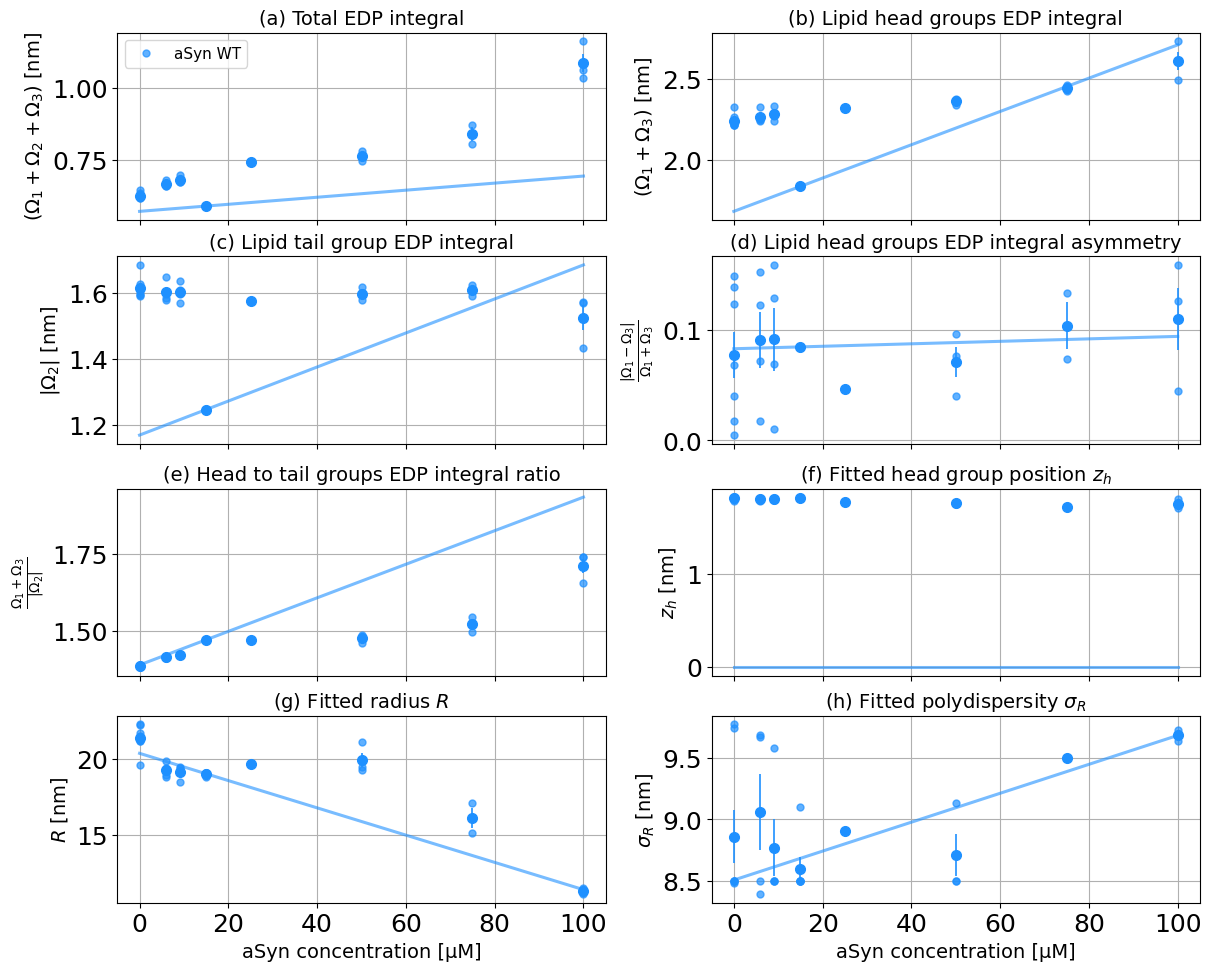

In [4]:
### Plot Omega Params POPG + aSyn 

DATASETS = {
    "WT": {
        "label": "aSyn WT",
        "color": "dodgerblue",
        "marker": "o",
        "best_fits": best_fits_POPG_aSynWT,
        "sample_asyn": {
            "BIX_S1": 0,
            "BVI_S11": 6,
            "BVI_S12": 9,
            "BVI_S13": 15,
            "BVI_S14": 25,
            "BVI_S15": 50,
            "BVI_S16": 75,
            "BVI_S17": 100,
        },
    },
}
from collections import defaultdict

# ============================================================================
# General helpers
# ============================================================================

def linear(x, m, n):
    return m * x + n


def mean_and_sem(values):
    """
    Ordinary arithmetic mean and standard error of the mean.

    Returns
    -------
    mean : float
    sem : float
        NaN if fewer than two values are available.
    """
    values = np.asarray(values, dtype=float)

    if values.size == 0:
        return np.nan, np.nan

    mean = np.mean(values)

    if values.size < 2:
        return mean, np.nan

    sem = np.std(values, ddof=1) / np.sqrt(values.size)
    return mean, sem


# ============================================================================
# Extract EDP quantities from one dataset
# ============================================================================

def collect_metrics(best_fits, sample_asyn):
    """
    Extract EDP quantities and fitted structural parameters.

    Every configuration is kept as an individual data point. No chi2
    weighting is performed anywhere in this step.
    """
    records = []

    for sample, asyn_conc in sample_asyn.items():
        fit_configs = best_fits[sample].get("ULV_spheric_asym_C4", {}).copy()
        # fit_configs.update(best_fits[sample].get("ULV_sph_asym_prot_layer", {}))

        for config_id, params in fit_configs.items():

            edp_params = params[2:8]

            (
                edp_tot,
                edp_hg_tot,
                edp_tg,
                edp_hg_asym,
                edp_hg_tg,
            ) = fit.EDP_analysis(edp_params)

            records.append({
                "sample": sample,
                "config": config_id,
                "aSyn": asyn_conc,

                "EDP_tot": edp_tot,
                "EDP_hg_tot": edp_hg_tot,
                "EDP_tg": abs(edp_tg),
                "EDP_hg_asym": edp_hg_asym,
                "EDP_hg_tg": edp_hg_tg,

                "R": params[0],
                "sigma_R": params[1],
                "z_h": params[7],
            })

    return records


# ============================================================================
# Group configurations by aSyn concentration and calculate mean + SEM
# ============================================================================

METRICS = (
    "EDP_tot",
    "EDP_hg_tot",
    "EDP_tg",
    "EDP_hg_asym",
    "EDP_hg_tg",
    "z_h",
    "R",
    "sigma_R",
)


def aggregate_by_concentration(records):
    """
    Calculate ordinary (unweighted) mean and SEM for each concentration.
    """
    groups = defaultdict(list)

    for record in records:
        groups[record["aSyn"]].append(record)

    concentrations = np.array(sorted(groups), dtype=float)
    means = {}
    sems = {}

    for metric in METRICS:

        metric_means = []
        metric_sems = []

        for concentration in concentrations:
            
            values = [
                record[metric]
                for record in groups[concentration]
            ]
            

            mean, sem = np.mean(values), np.std(values) / np.sqrt(len(values))

            metric_means.append(mean)
            metric_sems.append(sem)
            # if concentration == 1:
            #     print(f"Metric {metric}, concentration {concentration}")
            #     print(mean, sem, values)

        means[metric] = np.asarray(metric_means)
        sems[metric] = np.asarray(metric_sems)
        # print(f"Metric {metric}: means = {means[metric]}, sems = {sems[metric]}")

    return concentrations, means, sems


# ============================================================================
# Prepare all datasets
# ============================================================================

all_data = {}
print(DATASETS.items())
for dataset_name, dataset in DATASETS.items():

    records = collect_metrics(
        dataset["best_fits"],
        dataset["sample_asyn"],
    )

    concentrations, means, sems = aggregate_by_concentration(records)

    all_data[dataset_name] = {
        "records": records,
        "style": dataset,

        # Individual points
        "aSyn_all": np.array([r["aSyn"] for r in records]),
        "data": {
            metric: np.array([r[metric] for r in records])
            for metric in METRICS
        },

        # Mean values
        "aSyn_means": concentrations,
        "means": means,
        "sems": sems,
    }


# ============================================================================
# Plot configuration
# ============================================================================

PLOT_INFO = [
    (
        "EDP_tot",
        "(a) Total EDP integral",
        r"$(\Omega_1 + \Omega_2 + \Omega_3)$ [nm]",
    ),
    (
        "EDP_hg_tot",
        "(b) Lipid head groups EDP integral",
        r"$(\Omega_1 + \Omega_3)$ [nm]",
    ),
    (
        "EDP_tg",
        "(c) Lipid tail group EDP integral",
        r"$|\Omega_2|$ [nm]",
    ),
    (
        "EDP_hg_asym",
        "(d) Lipid head groups EDP integral asymmetry",
        r"$\frac{|\Omega_1-\Omega_3|}{\Omega_1+\Omega_3}$",
    ),
    (
        "EDP_hg_tg",
        "(e) Head to tail groups EDP integral ratio",
        r"$\frac{\Omega_1+\Omega_3}{|\Omega_2|}$",
    ),
    (
        "z_h",
        "(f) Fitted head group position $z_h$",
        r"$z_h$ [nm]",
    ),
    (
        "R",
        "(g) Fitted radius $R$",
        r"$R$ [nm]",
    ),
    (
        "sigma_R",
        "(h) Fitted polydispersity $\sigma_R$",
        r"$\sigma_R$ [nm]",
    ),
]


# ============================================================================
# Plot
# ============================================================================

# plt.rcParams.update({
#     "font.family": "serif",
#     "mathtext.fontset": "dejavuserif",
# })

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(12, 9.6),
    sharex=True,
    constrained_layout=True,
)

axes = axes.flatten()


for ax, (metric, title, ylabel) in zip(axes, PLOT_INFO):

    for dataset_name, dataset in all_data.items():

        style = dataset["style"]
        color = style["color"]
        marker = style["marker"]

        # ------------------------------------------------------------------
        # Individual fit results
        # ------------------------------------------------------------------
        # if metric == "EDP_tot":
        #     print(dataset["aSyn_all"])
        ax.plot(
            dataset["aSyn_all"],
            dataset["data"][metric],
            ls="None",
            marker=marker,
            markersize=5,
            color=color,
            alpha=0.7,
            label=style["label"],
        )

        # ------------------------------------------------------------------
        # Mean ± SEM
        # ------------------------------------------------------------------

        x_mean = dataset["aSyn_means"]
        y_mean = dataset["means"][metric]
        y_sem = dataset["sems"][metric]

        ax.errorbar(
            x_mean,
            y_mean,
            yerr=y_sem,
            ls="None",
            marker=marker,
            markersize=7,
            color=color,
            elinewidth=1.2,
            capsize=0,
            zorder=5,
        )

        # ------------------------------------------------------------------
        # Linear fit
        #
        # The means themselves are unweighted.
        # The regression uses the SEM as uncertainty weighting.
        # ------------------------------------------------------------------

        valid = (
            np.isfinite(x_mean)
            & np.isfinite(y_mean)
            & np.isfinite(y_sem)
            & (y_sem > 0)
        )


        x_fit_data = x_mean[valid]
        y_fit_data = y_mean[valid]
        y_fit_err = y_sem[valid]

        popt, pcov = curve_fit(
            linear,
            x_fit_data,
            y_fit_data,
            sigma=y_fit_err,
            p0=[0.0, 0.0],
            maxfev=20000,
        )

        parameter_errors = np.sqrt(np.diag(pcov))

        print(
            f"{dataset_name} – {metric}: "
            f"m = {popt[0]:.4g} ± {parameter_errors[0]:.4g}, "
            f"n = {popt[1]:.4g} ± {parameter_errors[1]:.4g}"
        )

        # Smooth fit line
        x_line = np.linspace(
            x_fit_data.min(),
            x_fit_data.max(),
            200,
        )

        ax.plot(
            x_line,
            linear(x_line, *popt),
            color=color,
            alpha=0.6,
            linewidth=2.2,
        )

    # ----------------------------------------------------------------------
    # Axes formatting
    # ----------------------------------------------------------------------

    ax.set_title(title, fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.grid(True)


# ============================================================================
# Legend and common x-axis labels
# ============================================================================

axes[0].legend(
    fontsize=11,
    frameon=True,
)

for ax in axes[-2:]:
    ax.set_xlabel(
        "aSyn concentration [µM]",
        fontsize=14,
    )


# ============================================================================
# Save / show
# ============================================================================

# target_folder = Path("C:/Users/riko05/Documents/8. SoSe 26/Code/BM29_data_and_analysis_2026/analysis_BM29_July2026/Results_and_Figures/Aug27/Plot_WT_A124T")
# fig.savefig(
#     target_folder / "EDP_metrics_spherical_WT_vs_A124T_stats.png",
#     dpi=600,
#     bbox_inches="tight",
# )

target_folder = Path("C:/Users/riko05/Documents/8. SoSe 26/Code/BM29_data_and_analysis_2026/analysis_BM29_July2026/Results_and_Figures/Sep1/EDP_metrics_for_E61V_and_E46K")
# fig.savefig(
#     target_folder / "EDP_metrics_sph_asym_WT_vs_A124T.png",
#     dpi=600,
#     bbox_inches="tight",
# )

plt.show()

<>:73: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:73: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\rikoh\AppData\Local\Temp\ipykernel_21888\1830063732.py:73: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  "(h) Fitted polydispersity $\sigma_R$",


WT – EDP_tot: m = 0.000712 ± 0.0024, n = 0.5785 ± 0.036
    R² = 0.0173, χ²_red = 217.0462, F = 0.0880, p = 0.7786
WT – EDP_hg_tot: m = 0.009924 ± 0.004847, n = 1.686 ± 0.07271
    R² = 0.4561, χ²_red = 557.3356, F = 4.1928, p = 0.09593
WT – EDP_tg: m = 0.004587 ± 0.00445, n = 1.177 ± 0.06677
    R² = 0.1752, χ²_red = 606.2361, F = 1.0623, p = 0.3499
WT – EDP_hg_asym: m = 9.542e-05 ± 0.0001487, n = 0.08309 ± 0.002236
    R² = 0.0761, χ²_red = 0.3402, F = 0.4117, p = 0.5494
WT – EDP_hg_tg: m = 0.005548 ± 0.000791, n = 1.389 ± 0.01181
    R² = 0.9077, χ²_red = 185.5368, F = 49.1934, p = 0.0009085
WT – z_h: m = 4.681e-16 ± 6.768e+10, n = 7.022e-15 ± 1.015e+12
    R² = -9636610700035501880453890048.0000, χ²_red = 66447202102522246928971388157952.0000, F = -5.0000, p = 1
WT – R: m = -0.08977 ± 0.005688, n = 20.39 ± 0.2022
    R² = 0.9803, χ²_red = 15.0805, F = 249.1135, p = 1.857e-05
WT – sigma_R: m = 0.01172 ± 0.001442, n = 8.512 ± 0.1373
    R² = 0.9429, χ²_red = 2.1314, F = 66.0252, p = 

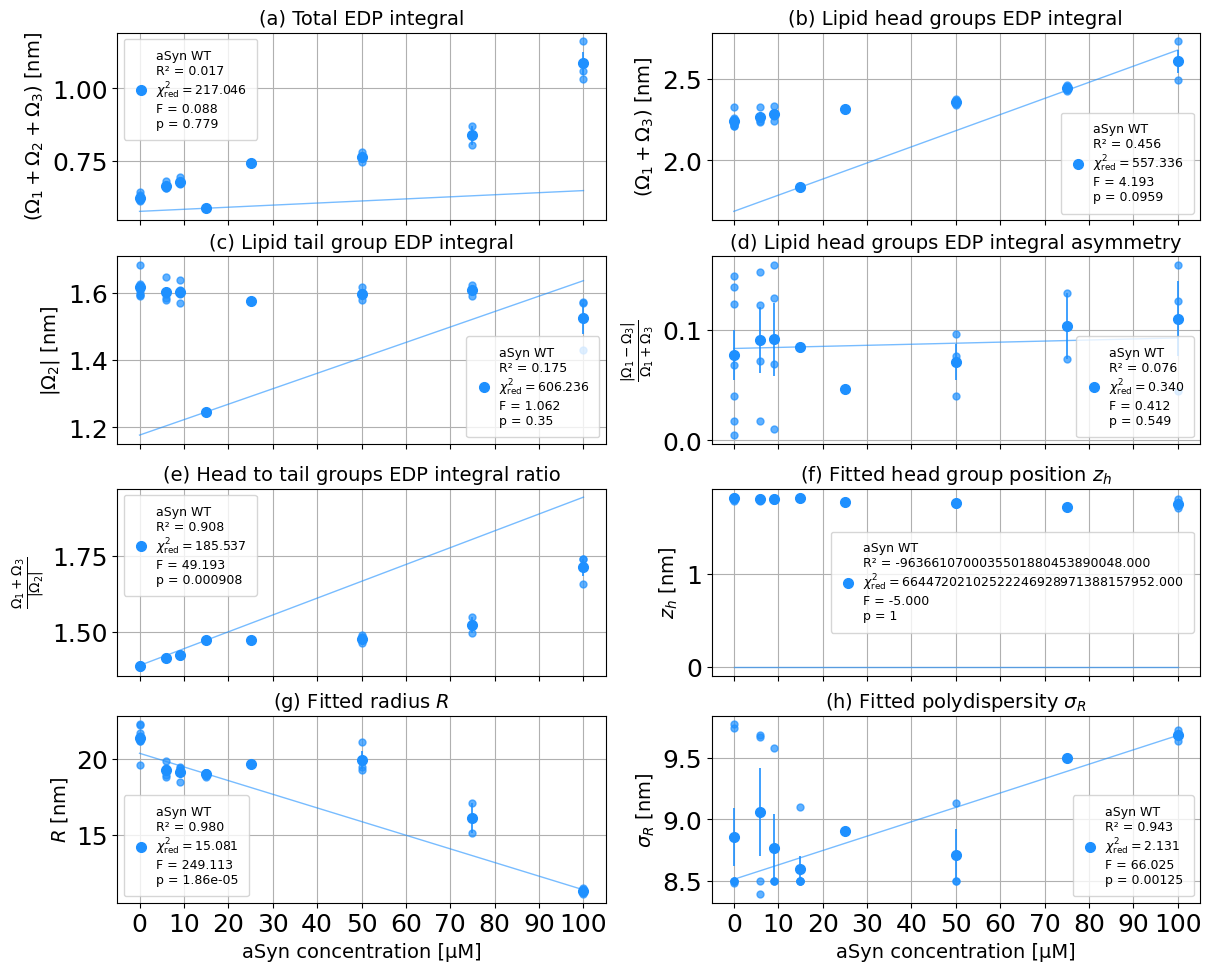

In [5]:
### Plot POPG + aSyn statistics

from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import f
from matplotlib.lines import Line2D


# =============================================================================
# Configuration
# =============================================================================




# =============================================================================
# Metrics
# =============================================================================

METRICS = (
    "EDP_tot",
    "EDP_hg_tot",
    "EDP_tg",
    "EDP_hg_asym",
    "EDP_hg_tg",
    "z_h",
    "R",
    "sigma_R",
)


PLOT_INFO = [
    (
        "EDP_tot",
        "(a) Total EDP integral",
        r"$(\Omega_1 + \Omega_2 + \Omega_3)$ [nm]",
    ),
    (
        "EDP_hg_tot",
        "(b) Lipid head groups EDP integral",
        r"$(\Omega_1 + \Omega_3)$ [nm]",
    ),
    (
        "EDP_tg",
        "(c) Lipid tail group EDP integral",
        r"$|\Omega_2|$ [nm]",
    ),
    (
        "EDP_hg_asym",
        "(d) Lipid head groups EDP integral asymmetry",
        r"$\frac{|\Omega_1-\Omega_3|}{\Omega_1+\Omega_3}$",
    ),
    (
        "EDP_hg_tg",
        "(e) Head to tail groups EDP integral ratio",
        r"$\frac{\Omega_1+\Omega_3}{|\Omega_2|}$",
    ),
    (
        "z_h",
        "(f) Fitted head group position $z_h$",
        r"$z_h$ [nm]",
    ),
    (
        "R",
        "(g) Fitted radius $R$",
        r"$R$ [nm]",
    ),
    (
        "sigma_R",
        "(h) Fitted polydispersity $\sigma_R$",
        r"$\sigma_R$ [nm]",
    ),
]


# =============================================================================
# Helper functions
# =============================================================================

def linear(x, m, n):
    return m * x + n


def mean_and_sem(values):
    """
    Calculate ordinary arithmetic mean and SEM.
    """
    values = np.asarray(values, dtype=float)

    if values.size == 0:
        return np.nan, np.nan

    mean = np.mean(values)

    if values.size < 2:
        return mean, np.nan

    sem = np.std(values, ddof=1) / np.sqrt(values.size)

    return mean, sem


def collect_metrics(best_fits, sample_asyn):
    """
    Extract all individual fit configurations.

    No chi2 weighting is applied.
    """
    records = []

    for sample, asyn_conc in sample_asyn.items():

        if sample not in best_fits:
            continue

        fit_configs = best_fits[sample].get("ULV_spheric_asym_C4", {}).copy()
        # fit_configs.update(best_fits[sample].get("ULV_sph_asym_prot_layer", {}))

        for config_id, params in fit_configs.items():

            edp_params = params[2:8]

            (
                edp_tot,
                edp_hg_tot,
                edp_tg,
                edp_hg_asym,
                edp_hg_tg,
            ) = fit.EDP_analysis(edp_params)

            records.append({
                "sample": sample,
                "config": config_id,
                "aSyn": asyn_conc,

                "EDP_tot": edp_tot,
                "EDP_hg_tot": edp_hg_tot,
                "EDP_tg": abs(edp_tg),
                "EDP_hg_asym": edp_hg_asym,
                "EDP_hg_tg": edp_hg_tg,

                "R": params[0],
                "sigma_R": params[1],
                "z_h": params[7],
            })

    return records


def aggregate_by_concentration(records):
    """
    Group individual fits by aSyn concentration and calculate
    ordinary mean + SEM.
    """
    groups = defaultdict(list)

    for record in records:
        groups[record["aSyn"]].append(record)

    concentrations = np.array(
        sorted(groups.keys()),
        dtype=float,
    )

    means = {}
    sems = {}

    for metric in METRICS:

        metric_means = []
        metric_sems = []

        for concentration in concentrations:

            values = [
                record[metric]
                for record in groups[concentration]
            ]

            mean, sem = mean_and_sem(values)

            metric_means.append(mean)
            metric_sems.append(sem)

        means[metric] = np.asarray(metric_means)
        sems[metric] = np.asarray(metric_sems)

    return concentrations, means, sems


def make_legend_handle(color, marker, label):
    """
    Create a clean legend handle for one dataset.
    """
    return Line2D(
        [0],
        [0],
        linestyle="None",
        marker=marker,
        markersize=7,
        color=color,
        label=label,
    )


# =============================================================================
# Collect all data
# =============================================================================

all_data = {}

for dataset_name, dataset in DATASETS.items():

    records = collect_metrics(
        dataset["best_fits"],
        dataset["sample_asyn"],
    )

    if not records:
        print(
            f"Warning: no records found for {dataset_name}"
        )
        continue

    concentrations, means, sems = aggregate_by_concentration(
        records
    )

    all_data[dataset_name] = {
        "records": records,
        "style": dataset,

        # Individual points
        "aSyn_all": np.array(
            [record["aSyn"] for record in records]
        ),

        "data": {
            metric: np.array(
                [record[metric] for record in records]
            )
            for metric in METRICS
        },

        # Means and SEMs
        "aSyn_means": concentrations,
        "means": means,
        "sems": sems,
    }


# =============================================================================
# Plot
# =============================================================================

# plt.rcParams.update({
#     "font.family": "serif",
#     "mathtext.fontset": "dejavuserif",
# })

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(12, 9.6),
    sharex=True,
    constrained_layout=True,
)

axes = axes.flatten()


# Store statistics for optional later use
fit_statistics = {}


for ax, (metric, title, ylabel) in zip(
    axes,
    PLOT_INFO,
):

    fit_statistics[metric] = {}

    legend_handles = []

    for dataset_name, dataset in all_data.items():

        style = dataset["style"]
        color = style["color"]
        marker = style["marker"]
        label = style["label"]

        # =====================================================================
        # Individual fit configurations
        # =====================================================================

        ax.plot(
            dataset["aSyn_all"],
            dataset["data"][metric],

            linestyle="None",
            marker=marker,
            markersize=5,

            color=color,
            alpha=0.7,
        )

        # =====================================================================
        # Mean ± SEM
        # =====================================================================

        x_mean = dataset["aSyn_means"]
        y_mean = dataset["means"][metric]
        y_sem = dataset["sems"][metric]

        ax.errorbar(
            x_mean,
            y_mean,
            yerr=y_sem,

            linestyle="None",
            marker=marker,
            markersize=7,

            color=color,
            elinewidth=1.2,
            capsize=0,

            zorder=5,
        )

        # =====================================================================
        # Linear fit + statistics
        # =====================================================================

        statistics = BM29.calculate_linear_fit_statistics(
            x_mean,
            y_mean,
            y_sem,
        )

        if statistics is None:
            print(
                f"{dataset_name} – {metric}: "
                "not enough valid points for linear fit."
            )
            continue

        fit_statistics[metric][dataset_name] = statistics

        popt = statistics["popt"]
        perr = statistics["perr"]

        # ---------------------------------------------------------------------
        # Print results
        # ---------------------------------------------------------------------

        print(
            f"{dataset_name} – {metric}: "
            f"m = {popt[0]:.4g} ± {perr[0]:.4g}, "
            f"n = {popt[1]:.4g} ± {perr[1]:.4g}"
        )

        print(
            f"    R² = {statistics['r_squared_weighted']:.4f}, "
            f"χ²_red = {statistics['reduced_chi_squared']:.4f}, "
            f"F = {statistics['f_stat']:.4f}, "
            f"p = {statistics['p_value']:.4g}"
        )

        # ---------------------------------------------------------------------
        # Smooth fit line
        # ---------------------------------------------------------------------

        x_valid = statistics["x"]

        x_line = np.linspace(
            x_valid.min(),
            x_valid.max(),
            200,
        )

        ax.plot(
            x_line,
            linear(x_line, *popt),

            color=color,
            alpha=0.6,
            linewidth=1.0,
        )

        # ---------------------------------------------------------------------
        # Legend entry containing dataset + statistics
        # ---------------------------------------------------------------------

        legend_label = BM29.format_statistics_label(
            label,
            statistics,
        )

        legend_handles.append(
            make_legend_handle(
                color,
                marker,
                legend_label,
            )
        )

    # =========================================================================
    # Axis formatting
    # =========================================================================

    ax.set_title(
        title,
        fontsize=14,
    )

    ax.set_ylabel(
        ylabel,
        fontsize=14,
    )

    ax.grid(True)

    ax.set_xticks(
        np.arange(0, 105, 10)
    )

    # =========================================================================
    # Subplot-specific legend
    # =========================================================================

    if legend_handles:
        ax.legend(
            handles=legend_handles,
            loc="best",
            fontsize=9,
            frameon=True,
            handlelength=1.2,
            handletextpad=0.6,
            borderpad=0.8,
        )


# =============================================================================
# Common x-axis labels
# =============================================================================

for ax in axes[-2:]:
    ax.set_xlabel(
        "aSyn concentration [µM]",
        fontsize=14,
    )


# =============================================================================
# Save / show
# =============================================================================

# target_folder = Path("figures")
# fig.savefig(
#     target_folder / "EDP_metrics_spherical_WT_vs_A124T_stats.png",
#     dpi=600,
#     bbox_inches="tight",
# )

# fig.savefig(
#     target_folder / "EDP_metrics_spherical_WT_vs_A124T_stats.svg",
#     bbox_inches="tight",
# )

plt.show()

In [2]:
# Trying to find consistent ULV_spheric_asym_lognormal fits
# # =============================================================================
# fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym_lognormal(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
# fit_function_name = "ULV_spheric_asym_C4_lognormal"
# DAY = "Sep15"
# task_name = "lognormal_BVI_S18"
# # =============================================================================
# p0_BVI_S14 = BM29.best_fits["BVI_S14"]["ULV_spheric_asym_C4_lognormal"][1]

# who = [
#     "BVI_S14",
#     "BVI_S15",
# ]
# for sample in who:
#     count = 0
    
#     block = sample.split("_")[0]
#     block_path = BM29.blockpath(block)
#     dir_names = [x.name for x in block_path.iterdir()]
#     for dir_name in dir_names:
#         if dir_name[:-13].endswith(sample):
#             sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
#             q, I, I_err_Poisson = np.loadtxt(sub_dat_path, unpack=True)

#     mask = (q >= 0.07) & (q <= 5.1)
#     q    = q[mask]
#     I    = I[mask]
#     I_err_Poisson = I_err_Poisson[mask]

#     Ierr = BM29.Poisson_error_focus_minimum_highq(q, I_err_Poisson)

#     thinning = 2
#     q_thinned = q[::thinning]
#     I_thinned = I[::thinning]
#     I_err_thinned = Ierr[::thinning]
    
#     # ========================== Setting Bounds ==============================
#     # p0         = [   R,    sigma_R,   rho_h1,   rho_h2,    sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,   c4] 
#     lower_bounds = [  13,          0,      0.8,      0.8,        0.13,      0.13,      0.5,    1.5,       0,    0] 
#     upper_bounds = [   25,          1,      2.5,      2.5,         0.6,       0.6,      1.2,      2,       1,    1] 
#     p0 = [13.4, 0.7451, 1.168, 1.723, 0.4556, 0.3019, 0.7631, 1.789, 4.515e-07, 0.0008046]

#     print(f"Now fitting with {fit_function_name} sample {sample} ...")            
#     #======================== Fit ===========================================
#     try:
#         popt, pcov = curve_fit(
#             fit_function,
#             q_thinned,
#             I_thinned,
#             sigma=I_err_thinned,
#             maxfev=5000,
#             p0=p0,
#             bounds=(lower_bounds, upper_bounds)
#         )
#     except RuntimeError:
#         print("Maximum number of evaluations reached — skipping this fit.")
#         continue

#     param_names = ["R_fit", "sigma_R_fit", "rho_h1_fit", "rho_h2_fit", "sigma_h1_fit", "sigma_h2_fit", "sigma_c_fit", "z_h_fit", "scale_fit", "c4_fit"]

#     perr = np.sqrt(np.diag(pcov))
#     fit_lib_entry = "["
#     for name, value in zip(param_names, popt):
#         globals()[name] = value
#         fit_lib_entry += f"{value:.4g}, "
#     fit_lib_entry = fit_lib_entry[:-2]
#     fit_lib_entry += "]"
#     print(fit_lib_entry)
#     chi2, info_text_print = fit.all_info(q, I, Ierr, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)

#     # this_file = Path(__file__).resolve()
#     # analysis_BM29_July2026 = this_file.parent.parent
#     # target_folder = analysis_BM29_July2026 / "Results_and_Figures" / DAY / task_name
#     # if not target_folder.exists():
#     #     target_folder.mkdir()

#     print("Fit successful with chi2 = ", chi2)
#     print(info_text_print)
#     # with open(target_folder/f"info_texts_{DAY}.txt", "a", encoding="utf-8") as k:
#     #     k.write(f"\n\n{BM29.sample_dict[sample]} fitted using {fit_function_name} with chi2 = {chi2}\n" + fit_lib_entry + "\n###########################################\n")

#     #=========================== Plot ===========================================
#     q_fit = np.linspace(min(q), max(q), 1000)
#     plt.close("all")
#     plt.figure(figsize=(12, 7.5))
#     plt.errorbar(q, I, Ierr, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
#     plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
#     plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
#     plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, c4_fit), color='black', label='pow law bgr')
#     plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, p0[-1]), color='black', label='initial bgr', ls="--")

#     plt.xlabel('$q [1/\\mathrm{nm}]$')
#     plt.ylabel('$I(q) [\\mathrm{cm}^{-1}]$')
#     plt.title(f'{BM29.sample_dict[sample]} \nusing {fit_function_name}')
#     plt.grid(True)
#     legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
#     legend.set_title(info_text_print)
#     plt.tight_layout()
#     # plt.savefig(target_folder / f"{sample}_{fit_function_name}_{count}_{DAY}.png",dpi=200, bbox_inches='tight', pad_inches=0.05)

#     [13, 0.6433, 1.166, 1.762, 0.4674, 0.3042, 0.7792, 1.783, 3.195e-07, 0.0008143]


['BVI_S11']
['BVI_S12']
['BVI_S14']
['BVI_S15']
['BVI_S16']
['BVI_S17']


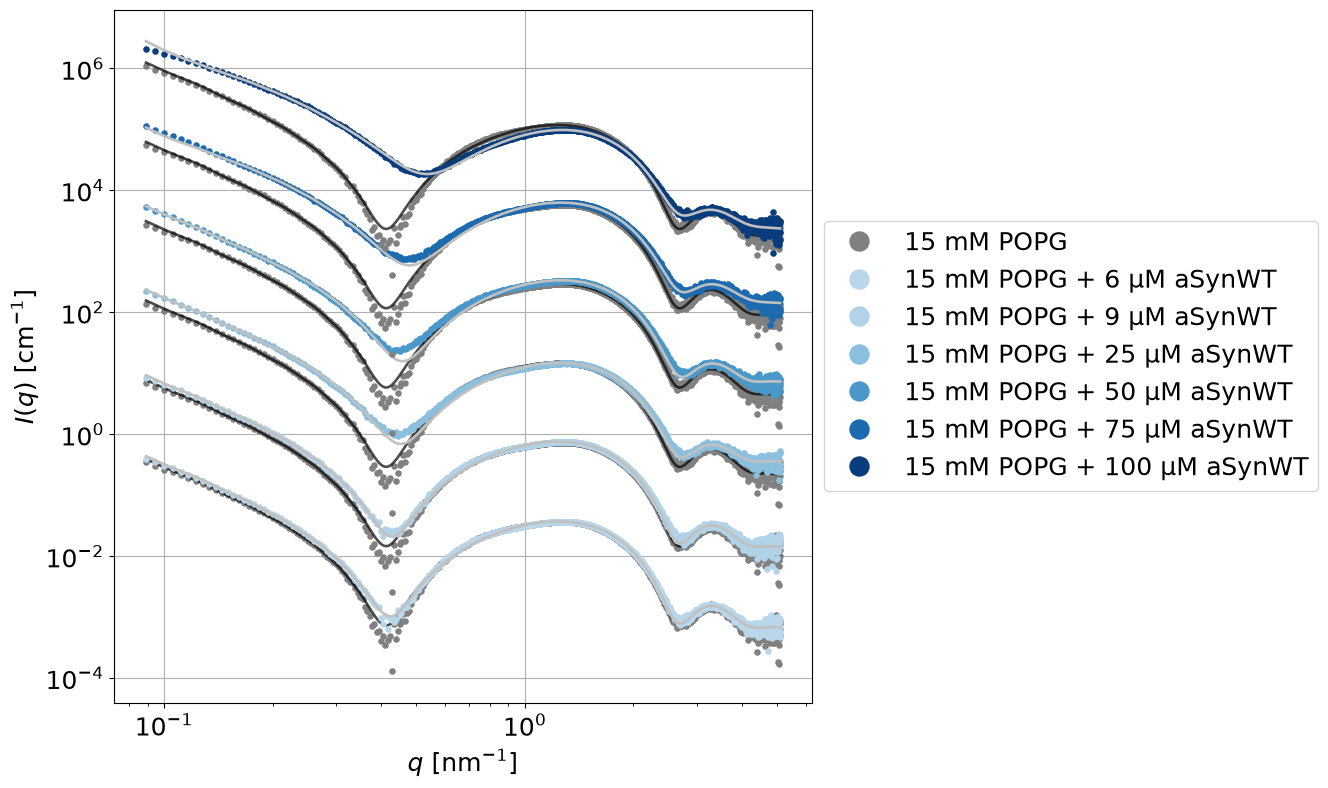

In [6]:
# SAXS curves + fits (BVI, POPG)
variant_dict = {
    "WT": ["BVI_S11",
           "BVI_S12",
        #    "BVI_S13",
           "BVI_S14",
           "BVI_S15",
           "BVI_S16",
           "BVI_S17"],
    "A124T": ["BVI_S19"],
    "E61V": ["BVI_S18"],
    "E46K": ["BVI_S20"],
}
shift_number = 20
from matplotlib import colormaps
from scipy.stats import lognorm
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
marker_standard = 3.7
lw_standard = 1.9
fit_color = "silver"
lv_color = "darkgrey"


fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym_lognormal(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)

def load_sample(sample):

    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)

    for dir_name in block_path.iterdir():

        if dir_name.name[:-13].endswith(sample):

            sub_dat_path = (
                dir_name
                / "avg_and_sub"
                / BM29.sample_dict[sample]
            )

            q, I, Ierr = np.loadtxt(
                sub_dat_path,
                unpack=True
            )

            mask = (q >= 0.085) & (q <= 5.1)

            return (
                q[mask],
                I[mask],
                Ierr[mask]
            )

def BVI_plot_together(who, title, variant="WT"):

    plt.close("all")

    f = plt.figure(figsize=(9, 9))
    shift_factors = {
        6:     shift_number**(0),
        9:     shift_number**(1),
        # 15:    shift_number**(2),
        25.0:   shift_number**(2),
        50.0:   shift_number**(3),
        75.0:   shift_number**(4),
        100.0:  shift_number**(5),
        # 15:    shift_number**(2),
        # 25.0:   shift_number**(3),
        # 50.0:   shift_number**(4),
        # 75.0:   shift_number**(5),
        # 100.0:  shift_number**(6),
    }
    c_min = 0
    c_max = 100
    if variant == "WT":
        colors = colormaps["Blues"]
    elif variant == "E61V":
        colors = colormaps["Greens"]
    elif variant == "E46K":
        colors = colormaps["Oranges"]
    elif variant == "A124T":
        colors = colormaps["Reds"]

    fit_function_name = "ULV_spheric_asym_C4_lognormal"
    lv_label_added = False

    concentrations_to_plot = sorted(
        set(
            BM29.concentrations[sample]
            for sample in who
        )
    )

    for concentration in concentrations_to_plot[1:]:

        prot_samples = [sample for sample in who[1:] if sample in variant_dict[variant] and BM29.concentrations[sample] == concentration]
        print(prot_samples)
        prot_sample = prot_samples[0]
        lv_sample = "BIX_S1"
        shift = shift_factors[concentration]

        # =====================================================
        # COLORS
        # =====================================================

        norm = (
            concentration - c_min
        ) / (
            c_max - c_min
        )
        # norm = LogNorm(vmin=1, vmax=100)


        # Avoid extremely pale colors
        norm = 0.25 + 0.70 * norm

        prot_color = colors(norm)

                # =====================================================
        # PURE LV
        # =====================================================

        q, I, Ierr = load_sample(lv_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                lv_sample
            ][fit_function_name][1]
        )

        # Apply EXACTLY THE SAME shift as WT and A124T
        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        # -----------------------------------------------------
        # Add pure LV to legend only once
        # -----------------------------------------------------

        if not lv_label_added:

            lv_label = BM29.nice_sample_names[lv_sample]
            lv_label_added = True

        else:

            lv_label = "_nolegend_"

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color="grey",
            markersize=marker_standard,
            label=lv_label
        )

        plt.plot(
            q,
            I_fit_shifted,
            color="black",
            label="_nolegend_",
            lw=lw_standard, #zorder=4
            alpha=0.7
        )

        # =====================================================
        # prot
        # =====================================================

        q, I, Ierr = load_sample(prot_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                prot_sample
            ][fit_function_name][1]
        )

        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color=prot_color,
            markersize=marker_standard,
            label=BM29.nice_sample_names[prot_sample]
        )

        plt.plot(
            q,
            I_fit_shifted,
            color=fit_color,
            label="_nolegend_",
            lw=lw_standard #, zorder=4
        )



    # =========================================================
    # Formatting
    # =========================================================

    plt.xscale("log")
    plt.yscale("log")

    # plt.title(title)

    plt.xlabel(r'$q\ [\mathrm{nm}^{-1}]$')
    plt.ylabel(r'$I(q)\ [\mathrm{cm}^{-1}]$')

    plt.grid()

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        alignment="left",
        markerscale=3.7
    )

    return f


# =============================================================
# Run
# =============================================================
variant = "WT"
who = ["BIX_S1"] + variant_dict[variant]
f = BVI_plot_together(
    who,
    "",
    variant=variant
)

target_folder = Path("/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/Results_and_Figures/BVI_fit_results_Oct06"
)

# =============================================================
# Save
# =============================================================

f.savefig(
    target_folder / f"POPG_curves_n_fits_{variant}.png",
    dpi=700,
    bbox_inches="tight"
)
plt.show(f)

BIX_S1_15mM_POPG 10.79
BVI_S11_15mM_POPG_6uM_aSynWT 10.07
BVI_S12_15mM_POPG_9uM_aSynWT 11.95
BVI_S14_15mM_POPG_25uM_aSynWT 12.5
BVI_S15_15mM_POPG_50uM_aSynWT 12.5
BVI_S16_15mM_POPG_75uM_aSynWT 22.11
BVI_S17_15mM_POPG_100uM_aSynWT 20.57


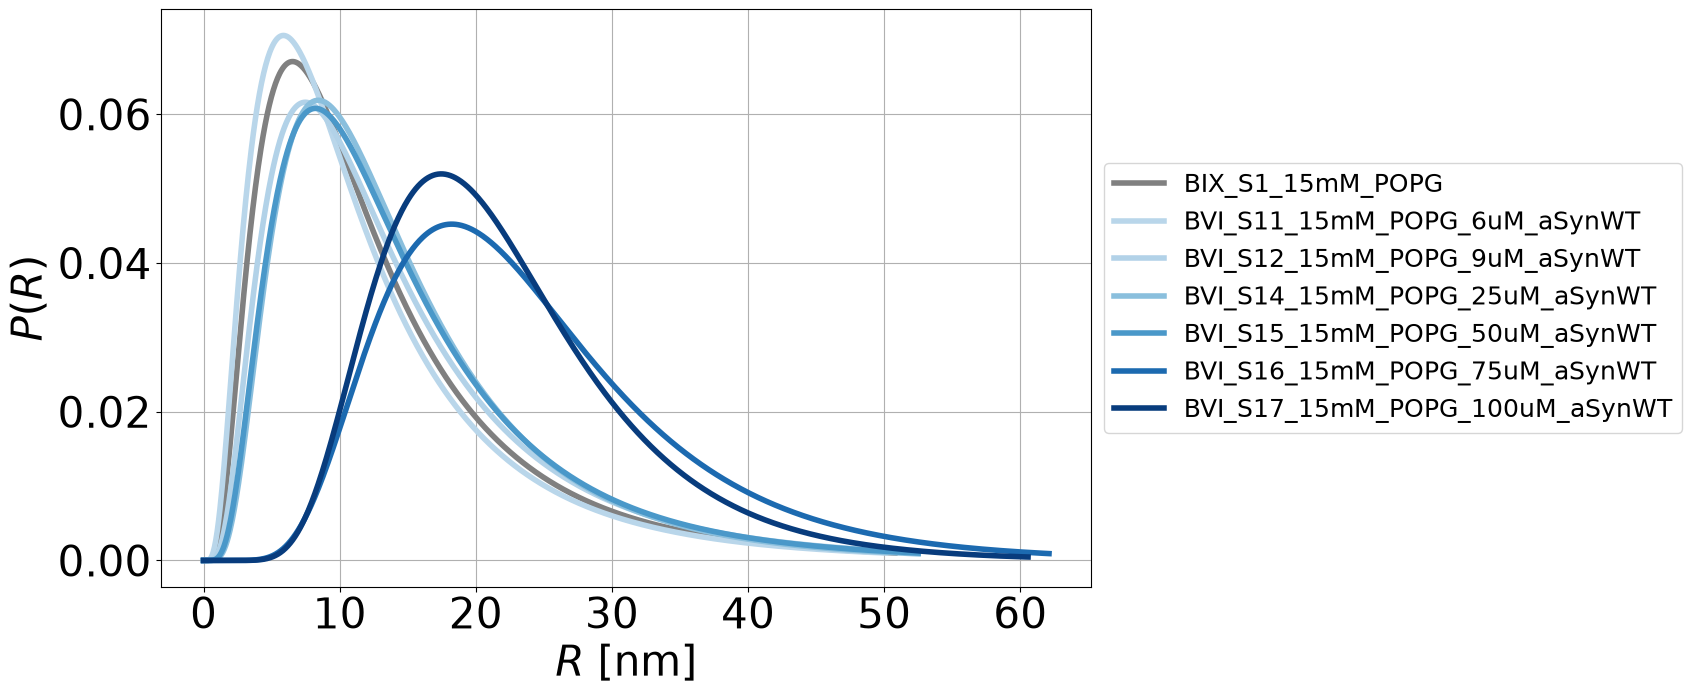

In [9]:
# POPG lognorm polydisp
target_folder = Path("/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/Results_and_Figures/BVI_fit_results_Oct06")

who = [
    "BIX_S1",
    "BVI_S11",
    "BVI_S12",
        #    "BVI_S13",
    "BVI_S14",
    "BVI_S15",
    "BVI_S16",
    "BVI_S17",
    # "BVI_S18",
    # "BVI_S19",
    # "BVI_S20",
]
for sample in who:
    R = BM29.best_fits[sample]["ULV_spheric_asym_C4_lognormal"][1][0]
    print(BM29.sample_dict[sample], R)
g = BM29.plot_together_lognorm_polydisp(who)
g.savefig(
    target_folder / f"POPG_lognorm_polydisp_{variant}.png",
    dpi=500,
    bbox_inches="tight"
)

BIX_S1_15mM_POPG 10.79
BVI_S14_15mM_POPG_25uM_aSynWT 12.5
BVI_S18_15mM_POPG_25uM_aSynE61V 12.68
BVI_S19_15mM_POPG_25uM_aSynA124T 12
BVI_S20_15mM_POPG_25uM_aSynE46K 9.001


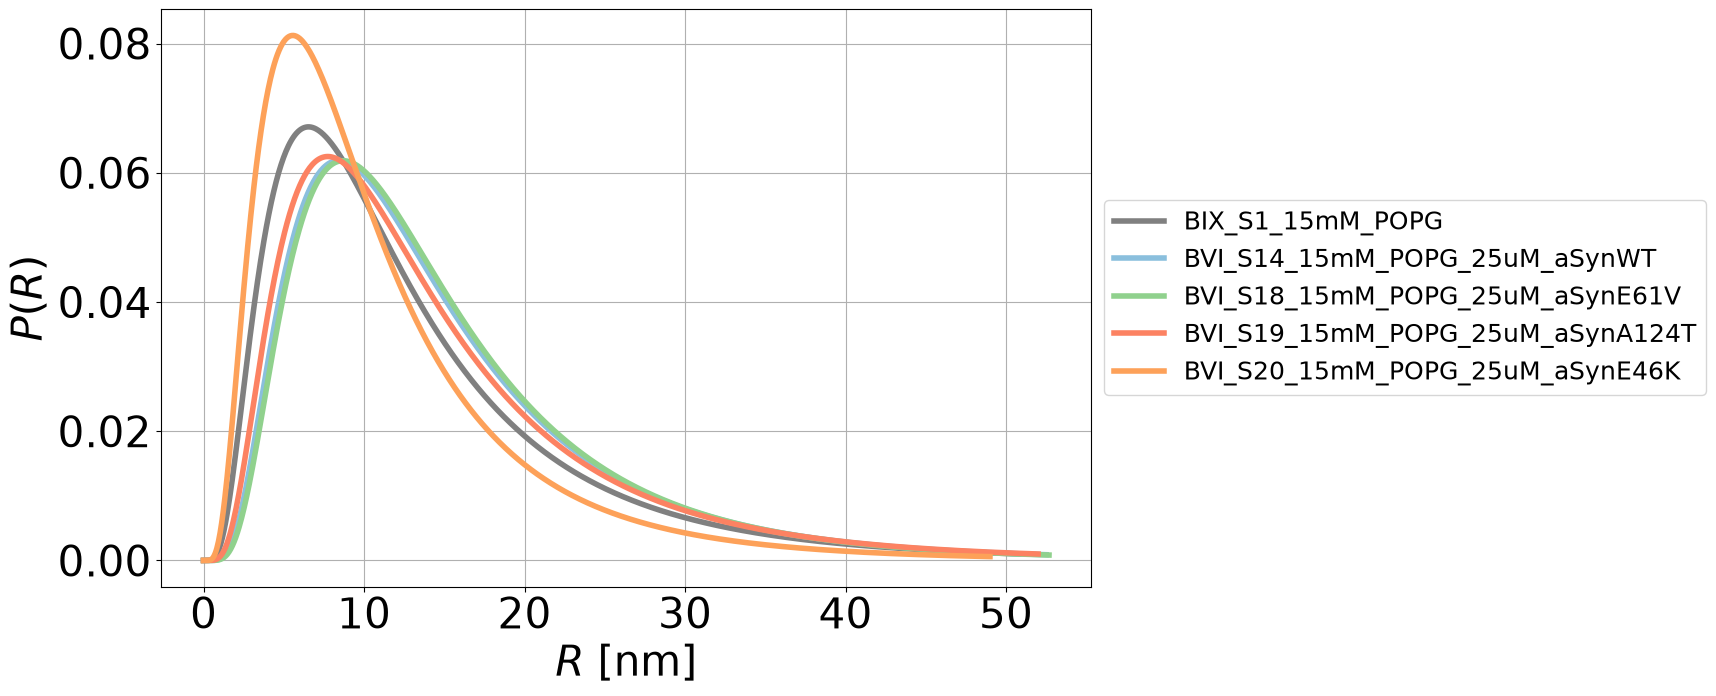

In [9]:
# POPG lognorm polydisp VARIANTS
target_folder = Path("/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/Results_and_Figures/BVI_fit_results_Oct06")

who = [
    "BIX_S1",
    # "BVI_S11",
    # "BVI_S12",
        #    "BVI_S13",
    "BVI_S14",
    # "BVI_S15",
    # "BVI_S16",
    # "BVI_S17",
    "BVI_S18",
    "BVI_S19",
    "BVI_S20",
]
for sample in who:
    R = BM29.best_fits[sample]["ULV_spheric_asym_C4_lognormal"][1][0]
    print(BM29.sample_dict[sample], R)
g = BM29.plot_together_lognorm_polydisp(who)
g.savefig(
    target_folder / f"POPG_lognorm_polydisp_variants.png",
    dpi=500,
    bbox_inches="tight"
)

['BVI_S1']
['BVI_S2']
['BVI_S3']
['BVI_S4']
['BVI_S5']
['BVI_S6']
['BVI_S7']


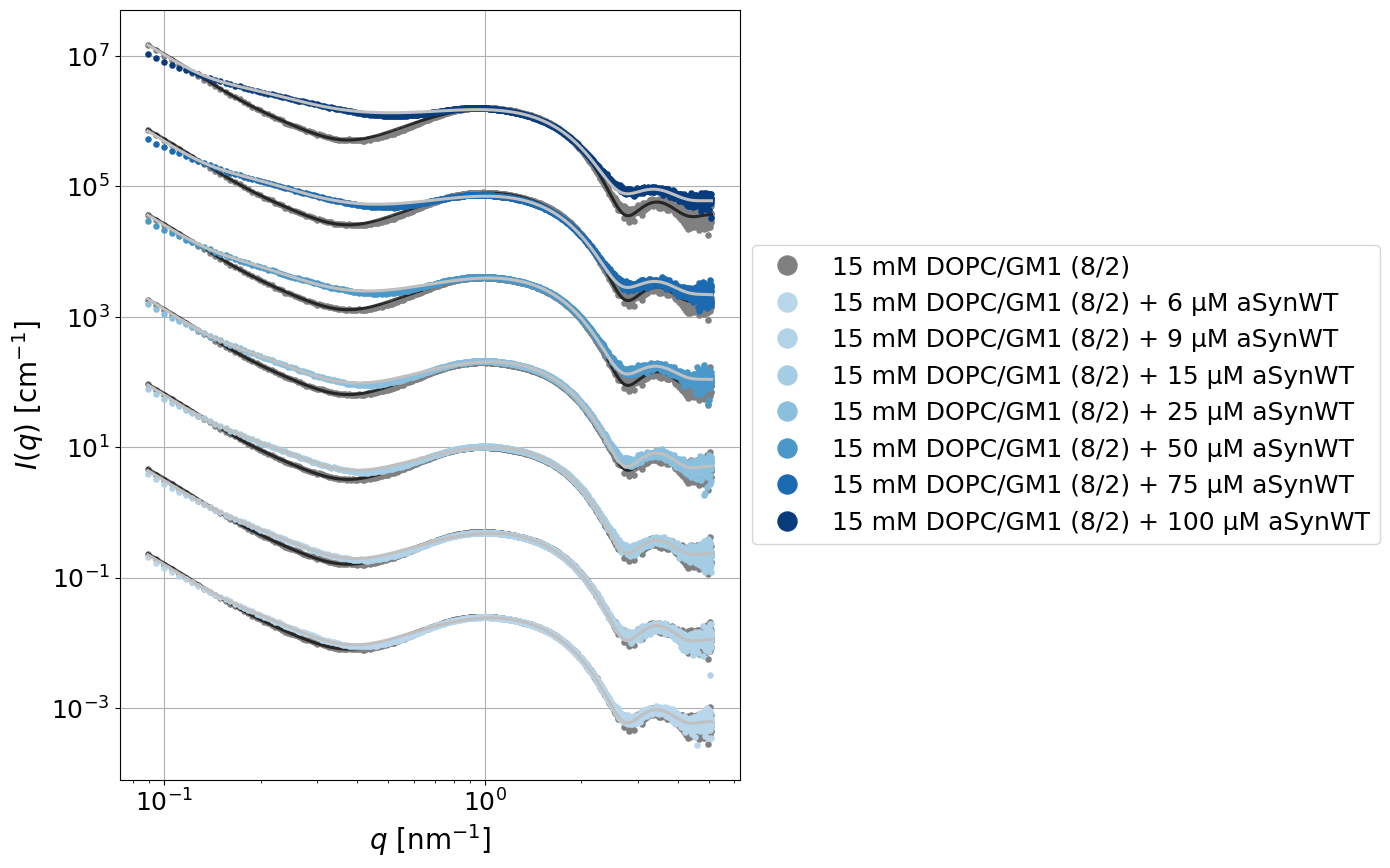

In [2]:
# SAXS curves + fits (BVI, DOPC/GM1)
variant_dict = {
    "WT": ["BVI_S1",
           "BVI_S2",
           "BVI_S3",
           "BVI_S4",
           "BVI_S5",
           "BVI_S6",
           "BVI_S7"],
    "A124T": ["BVI_S9"],
    "E61V": ["BVI_S8"],
    "E46K": ["BVI_S10"],
}
shift_number = 20
from matplotlib import colormaps
from scipy.stats import lognorm
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
marker_standard = 3.7
lw_standard = 2.2
fit_color = "silver"
lv_color = "darkgrey"


fit_function = lambda q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, c4: fit.ULV_lognormal_sph_asym_prot_layer(q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, 0, 0, c4)
def load_sample(sample):

    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)

    for dir_name in block_path.iterdir():

        if dir_name.name[:-13].endswith(sample):

            sub_dat_path = (
                dir_name
                / "avg_and_sub"
                / BM29.sample_dict[sample]
            )

            q, I, Ierr = np.loadtxt(
                sub_dat_path,
                unpack=True
            )

            mask = (q >= 0.085) & (q <= 5.1)

            return (
                q[mask],
                I[mask],
                Ierr[mask]
            )

def BVI_plot_together(who, title, variant="WT"):

    plt.close("all")

    f = plt.figure(figsize=(8, 10))
    shift_factors = {
        6:     shift_number**(0),
        9:     shift_number**(1),
        15:    shift_number**(2),
        25.0:   shift_number**(3),
        50.0:   shift_number**(4),
        75.0:   shift_number**(5),
        100.0:  shift_number**(6),
    }
    c_min = 0
    c_max = 100
    if variant == "WT":
        colors = colormaps["Blues"]
    elif variant == "E61V":
        colors = colormaps["Greens"]
    elif variant == "E46K":
        colors = colormaps["Oranges"]
    elif variant == "A124T":
        colors = colormaps["Reds"]

    fit_function_name = "ULV_lognormal_sph_asym_prot_layer"
    lv_label_added = False

    concentrations_to_plot = sorted(
        set(
            BM29.concentrations[sample]
            for sample in who
        )
    )

    for concentration in concentrations_to_plot[1:]:

        prot_samples = [sample for sample in who[1:] if sample in variant_dict[variant] and BM29.concentrations[sample] == concentration]
        print(prot_samples)
        prot_sample = prot_samples[0]
        lv_sample = "BIX_S2"
        shift = shift_factors[concentration]

        # =====================================================
        # COLORS
        # =====================================================

        norm = (
            concentration - c_min
        ) / (
            c_max - c_min
        )
        # norm = LogNorm(vmin=1, vmax=100)


        # Avoid extremely pale colors
        norm = 0.25 + 0.70 * norm

        prot_color = colors(norm)

                # =====================================================
        # PURE LV
        # =====================================================

        q, I, Ierr = load_sample(lv_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                lv_sample
            ][fit_function_name][1]
        )

        # Apply EXACTLY THE SAME shift as WT and A124T
        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        # -----------------------------------------------------
        # Add pure LV to legend only once
        # -----------------------------------------------------

        if not lv_label_added:

            lv_label = BM29.nice_sample_names[lv_sample]
            lv_label_added = True

        else:

            lv_label = "_nolegend_"

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color="grey",
            markersize=marker_standard,
            label=lv_label
        )

        plt.plot(
            q,
            I_fit_shifted,
            color="black",
            label="_nolegend_",
            lw=lw_standard, #zorder=4
            alpha=0.7
        )

        # =====================================================
        # prot
        # =====================================================

        q, I, Ierr = load_sample(prot_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                prot_sample
            ][fit_function_name][1]
        )

        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color=prot_color,
            markersize=marker_standard,
            label=BM29.nice_sample_names[prot_sample]
        )

        plt.plot(
            q,
            I_fit_shifted,
            color=fit_color,
            label="_nolegend_",
            lw=lw_standard #, zorder=4
        )



    # =========================================================
    # Formatting
    # =========================================================

    plt.xscale("log")
    plt.yscale("log")

    # plt.title(title)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    plt.xlabel(r'$q\ [\mathrm{nm}^{-1}]$', fontsize=20)
    plt.ylabel(r'$I(q)\ [\mathrm{cm}^{-1}]$', fontsize=20)

    plt.grid()

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        alignment="left",
        markerscale=3.7
    )

    return f


# =============================================================
# Run
# =============================================================
variant = "WT"
who = ["BIX_S2"] + variant_dict[variant]
f = BVI_plot_together(
    who,
    "",
    variant=variant
)

target_folder = Path("C:/Users/rikoh/Documents/Physik Göttingen&Grenoble 2022-2026/8. SoSe 26/SHK Synaptische Proteine, Lipidmembranen SoSe 2026/Code/BM29_data_and_analysis/analysis_BM29_2026/Results_and_Figures/BVI_fit_results_Oct06"
)

# =============================================================
# Save
# =============================================================

f.savefig(
    target_folder / f"DOPC_GM1_curves_n_fits_{variant}.png",
    dpi=700,
    bbox_inches="tight"
)
plt.show(f)

In [2]:
# DOPC/GM1 lognorm polydisp
who = [
    "BIX_S2",
    "BVI_S1",
    "BVI_S2",
    "BVI_S3",
    "BVI_S4",
    "BVI_S5",
    "BVI_S6",
    "BVI_S7"
]
target_folder = Path("C:/Users/rikoh/Documents/Physik Göttingen&Grenoble 2022-2026/8. SoSe 26/SHK Synaptische Proteine, Lipidmembranen SoSe 2026/Code/BM29_data_and_analysis/analysis_BM29_2026/Results_and_Figures/BVI_fit_results_Oct06")
for sample in who:
    R = BM29.best_fits[sample]["ULV_lognormal_sph_asym_prot_layer"][1][0]
    print(BM29.sample_dict[sample], R)
g = BM29.plot_together_lognorm_polydisp(who, fit_function_name="ULV_lognormal_sph_asym_prot_layer")
g.savefig(
    target_folder / f"DOPC_GM1_lognorm_polydisp_WT.png",
    dpi=500,
    bbox_inches="tight"
)
f = BM29.EDP_plot_together(who, title="DOPC/GM1 (8/2)", fit_function="ULV_lognormal_sph_asym_prot_layer")
f.savefig(
    target_folder / f"DOPC_GM1_EDPs_WT.png",
    dpi=500,
    bbox_inches="tight"
)

BIX_S2_15mM_DOPC_GM1_80_20 11.55
BVI_S1_15mM_DOPC_GM1_6uM_aSynWT 13.67
BVI_S2_15mM_DOPC_GM1_9uM_aSynWT 14.18
BVI_S3_15mM_DOPC_GM1_15uM_aSynWT 14.59
BVI_S4_15mM_DOPC_GM1_25uM_aSynWT 14.54
BVI_S5_15mM_DOPC_GM1_50uM_aSynWT 15.17
BVI_S6_15mM_DOPC_GM1_75uM_aSynWT 15.16
BVI_S7_15mM_DOPC_GM1_100uM_aSynWT 15


['BVI_S4']
['BVI_S9']
['BVI_S8']
['BVI_S10']


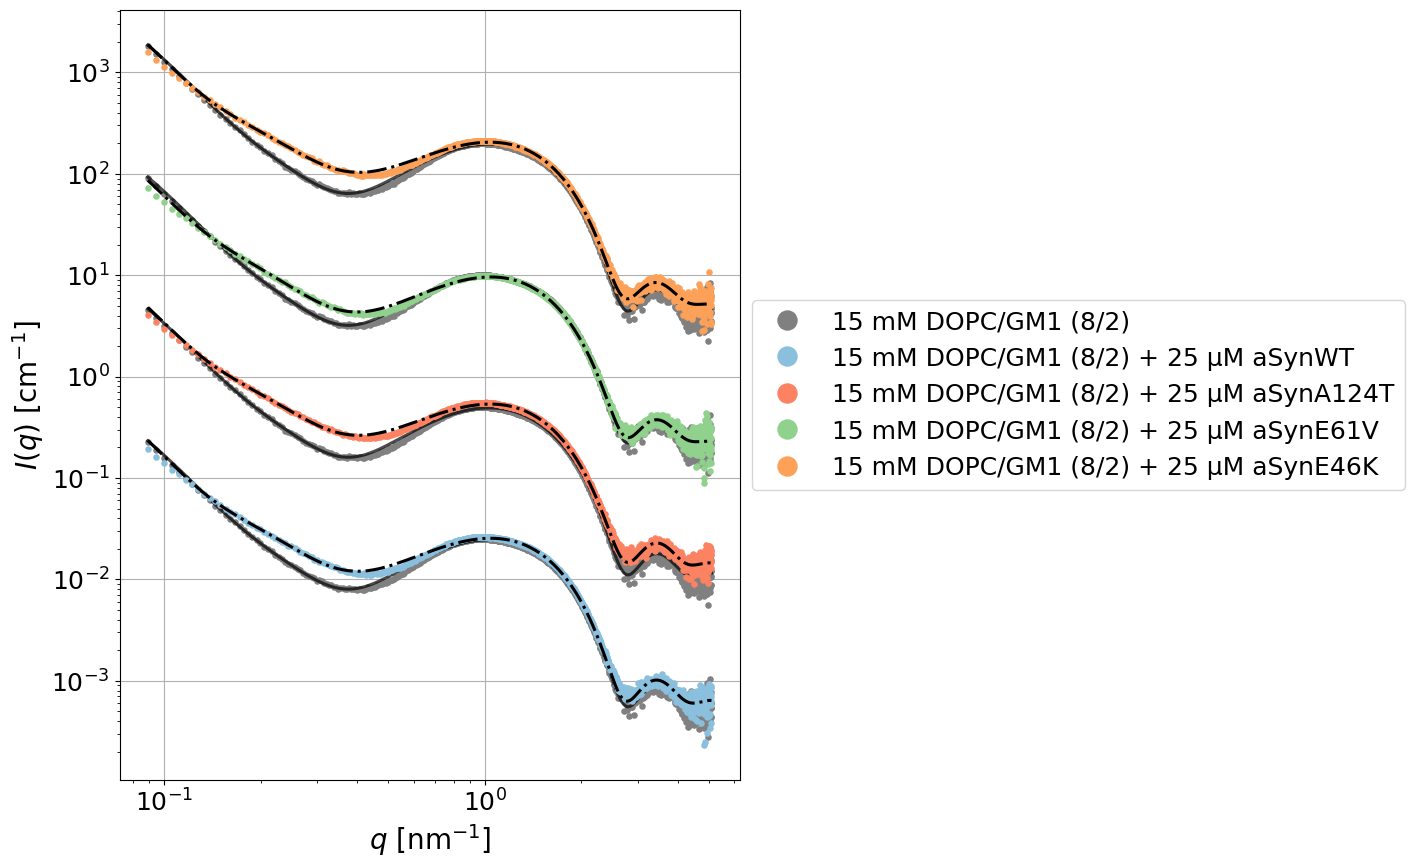

In [ ]:
# SAXS curves + fits (BVI, DOPC/GM1, variants)
variant_dict = {
    "WT": [#"BVI_S1",
        #    "BVI_S2",
        #    "BVI_S3",
           "BVI_S4",],
        #    "BVI_S5",
        #    "BVI_S6",
        #    "BVI_S7"],
    "A124T": ["BVI_S9"],
    "E61V": ["BVI_S8"],
    "E46K": ["BVI_S10"],
}
shift_number = 20
from matplotlib import colormaps
from scipy.stats import lognorm
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
marker_standard = 3.7
lw_standard = 2.2
fit_color = "black"
lv_color = "darkgrey"


fit_function = lambda q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, c4: fit.ULV_lognormal_sph_asym_prot_layer(q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, 0, 0, c4)
def load_sample(sample):

    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)

    for dir_name in block_path.iterdir():

        if dir_name.name[:-13].endswith(sample):

            sub_dat_path = (
                dir_name
                / "avg_and_sub"
                / BM29.sample_dict[sample]
            )

            q, I, Ierr = np.loadtxt(
                sub_dat_path,
                unpack=True
            )

            mask = (q >= 0.085) & (q <= 5.1)

            return (
                q[mask],
                I[mask],
                Ierr[mask]
            )

def BVI_plot_together(who):

    plt.close("all")

    f = plt.figure(figsize=(8, 10))
    shift_factors = {
        "WT":     shift_number**(0),
        "A124T":     shift_number**(1),
        "E61V":    shift_number**(2),
        "E46K":   shift_number**(3),
    }
    c_min = 0
    c_max = 100
    fit_function_name = "ULV_lognormal_sph_asym_prot_layer"
    lv_label_added = False

    for variant in variant_dict.keys():
        if variant == "WT":
            colors = colormaps["Blues"]
        elif variant == "E61V":
            colors = colormaps["Greens"]
        elif variant == "E46K":
            colors = colormaps["Oranges"]
        elif variant == "A124T":
            colors = colormaps["Reds"]

        prot_samples = [sample for sample in who[1:] if sample in variant_dict[variant]]
        print(prot_samples)
        prot_sample = prot_samples[0]
        lv_sample = "BIX_S2"
        shift = shift_factors[variant]

        # =====================================================
        # COLORS
        # =====================================================

        norm = (
            BM29.concentrations[prot_sample] - c_min
        ) / (
            c_max - c_min
        )
        # norm = LogNorm(vmin=1, vmax=100)


        # Avoid extremely pale colors
        norm = 0.25 + 0.70 * norm

        prot_color = colors(norm)

                # =====================================================
        # PURE LV
        # =====================================================

        q, I, Ierr = load_sample(lv_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                lv_sample
            ][fit_function_name][1]
        )

        # Apply EXACTLY THE SAME shift as WT and A124T
        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        # -----------------------------------------------------
        # Add pure LV to legend only once
        # -----------------------------------------------------

        if not lv_label_added:

            lv_label = BM29.nice_sample_names[lv_sample]
            lv_label_added = True

        else:

            lv_label = "_nolegend_"

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color="grey",
            markersize=marker_standard,
            label=lv_label
        )

        plt.plot(
            q,
            I_fit_shifted,
            color="black",
            label="_nolegend_",
            lw=lw_standard, #zorder=4
            alpha=0.7
        )

        # =====================================================
        # prot
        # =====================================================

        q, I, Ierr = load_sample(prot_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                prot_sample
            ][fit_function_name][1]
        )

        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color=prot_color,
            markersize=marker_standard,
            label=BM29.nice_sample_names[prot_sample]
        )

        plt.plot(
            q,
            I_fit_shifted,
            color=fit_color,
            label="_nolegend_",
            lw=lw_standard, #, zorder=4
            ls="-.",
        )



    # =========================================================
    # Formatting
    # =========================================================

    plt.xscale("log")
    plt.yscale("log")

    # plt.title(title)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    plt.xlabel(r'$q\ [\mathrm{nm}^{-1}]$', fontsize=20)
    plt.ylabel(r'$I(q)\ [\mathrm{cm}^{-1}]$', fontsize=20)

    plt.grid()

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        alignment="left",
        markerscale=3.7
    )

    return f


# =============================================================
# Run
# =============================================================
who = ["BIX_S2"] + ["BVI_S4",] + ["BVI_S9"] + ["BVI_S8"] + ["BVI_S10"]
f = BVI_plot_together(
    who,
)

target_folder = Path("C:/Users/rikoh/Documents/Physik Göttingen&Grenoble 2022-2026/8. SoSe 26/SHK Synaptische Proteine, Lipidmembranen SoSe 2026/Code/BM29_data_and_analysis/analysis_BM29_2026/Results_and_Figures/BVI_fit_results_Oct06"
)

# =============================================================
# Save
# =============================================================
# f.savefig(
#     target_folder / f"DOPC_GM1_curves_n_fits_variants.png",
#     dpi=700,
#     bbox_inches="tight"
# )
plt.show(f)

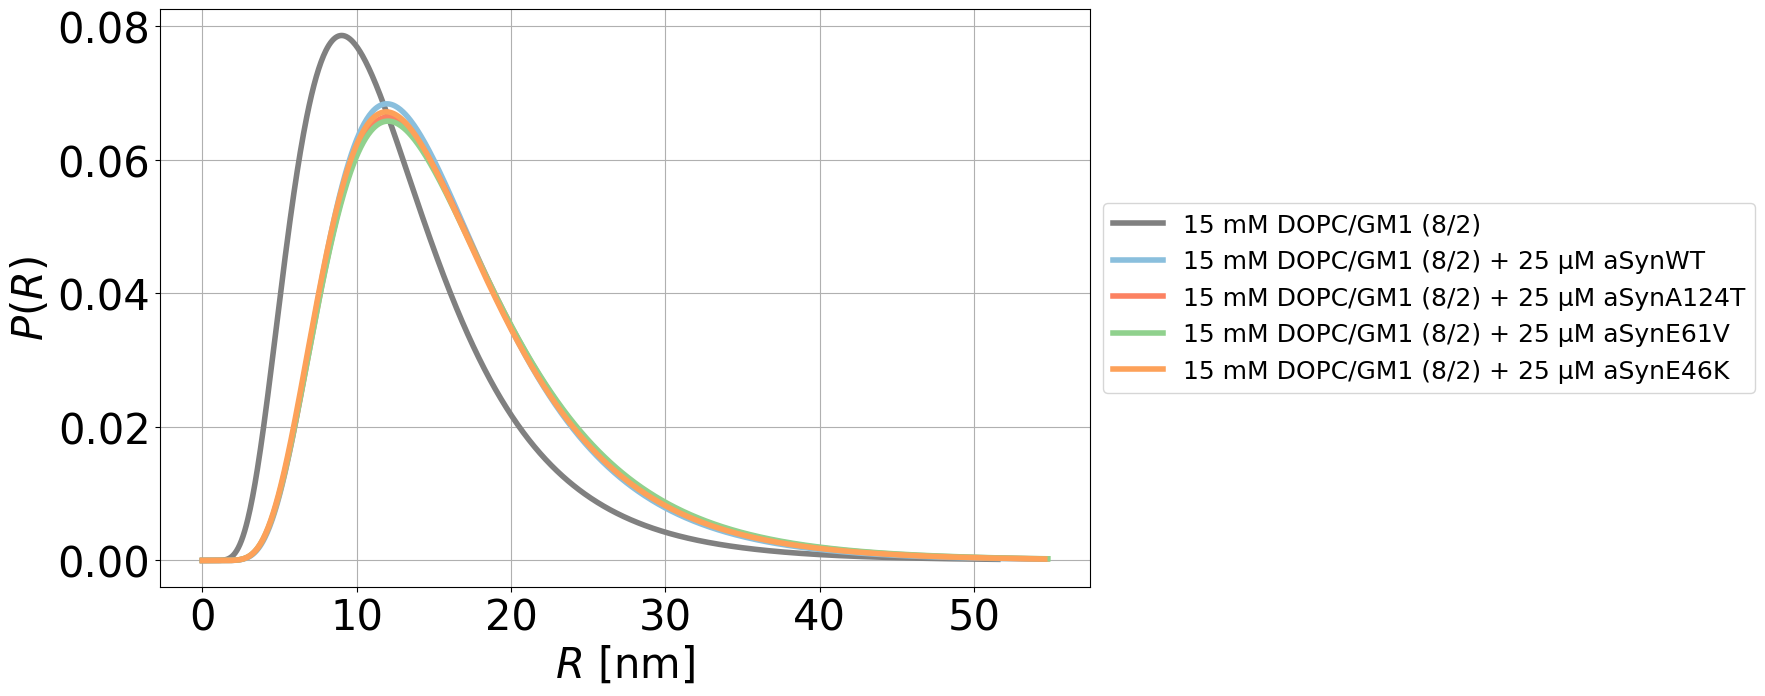

In [ ]:
# DOPC_GM1_variants_lognorm_polydisp
who = ["BIX_S2"] + ["BVI_S4",] + ["BVI_S9"] + ["BVI_S8"] + ["BVI_S10"]
target_folder = Path("C:/Users/rikoh/Documents/Physik Göttingen&Grenoble 2022-2026/8. SoSe 26/SHK Synaptische Proteine, Lipidmembranen SoSe 2026/Code/BM29_data_and_analysis/analysis_BM29_2026/Results_and_Figures/BVI_fit_results_Oct06")
g = BM29.EDP_plot_together(who, "", fit_function="ULV_lognormal_sph_asym_prot_layer")
f = BM29.plot_together_lognorm_polydisp(who, fit_function_name="ULV_lognormal_sph_asym_prot_layer")
f.savefig(
    target_folder / f"DOPC_GM1_variants_lognorm_polydisp.png",
    dpi=400,
    bbox_inches="tight"
)
# g.savefig(
#     target_folder / f"DOPC_GM1_variants_EDPs.png",
#     dpi=400,
#     bbox_inches="tight"
# )

In [6]:
best_fits_PCPS_aSynWT = {
    'BIX_S15': {     #: "15 mM DOPC/DOPS (8/2) + 6 μM aSynWT",
        'ULV_spheric_asym_C4': { 
            1: [17.06, 2.762, 1.538, 1.006, 0.3722, 0.3436, 0.8049, 1.778, 0.0001357, 0.0005374],
        },
        "ULV_spheric_asym_C4_lognormal": {
        },
    },
    'BIX_S16': {     
        'ULV_spheric_asym_C4': { 
            1: [17.01, 2.854, 1.528, 1.034, 0.3769, 0.3362, 0.8107, 1.774, 0.0001385, 0.0005207],
        },
        "ULV_spheric_asym_C4_lognormal": {
        },
    },
    'BIX_S17': {     
        'ULV_spheric_asym_C4': { 
            1: [16.97, 3.06, 1.481, 1.052, 0.3759, 0.3049, 0.7662, 1.784, 0.0001407, 0.000602],
        },
        "ULV_spheric_asym_C4_lognormal": {
        },
    },
    'BIX_S18': {     
        'ULV_spheric_asym_C4': { 
            1: [16.58, 4.304, 1.74, 0.8465, 0.3303, 0.3479, 0.751, 1.785, 0.000144, 0.0006345],
            2: [16.63, 4.292, 1.4, 1.264, 0.3956, 0.2214, 0.718, 1.798, 0.0001488, 0.0006404],
            # 3: [8, 4.981, 1.142, 1.352, 0.3632, 0.3353, 0.7796, 1.778, 0.0004647, 0.000633],
        },
    },
    'BIX_S19': {     
        'ULV_spheric_asym_C4': { 
            1: [17.2, 5.494, 1.674, 1, 0.3456, 0.2429, 0.6897, 1.801, 0.0001375, 0.0007067],
            3: [17.07, 5.518, 1.808, 1.2, 0.4262, 0.3127, 1, 1.741, 0.0001179, 0.0006885],
            4: [17.6, 5.476, 1.4, 1.4, 0.4024, 0.1697, 0.6719, 1.805, 0.0001388, 0.0007463],
        },
    },
    'BVII_S5': {     
        'ULV_spheric_asym_C4': { 
            # 1: [8.375, 6.267, 0.9268, 1.738, 0.277, 0.2665, 0.6375, 1.815, 0.0004056, 0.0006709],
            1: [9, 6.11, 1.4, 1.4, 0.1869, 0.3348, 0.6469, 1.813, 0.0003781, 0.0007477],
            2: [18.85, 6.191, 1.6, 1.6, 0.3674, 0.1284, 0.6484, 1.812, 0.0001153, 0.0007696],
            3: [19.2, 6.119, 1.6, 1.083, 0.3777, 0.2, 0.6742, 1.801, 0.0001095, 0.0007979],
            4: [15.35, 7.075, 2.113, 1, 0.389, 0.3476, 1, 1.737, 0.0001244, 0.0007139],
            5: [18.43, 6.202, 2.186, 0.722, 0.2673, 0.2758, 0.6371, 1.815, 0.0001172, 0.0006718],
            6: [9, 6.286, 1.089, 1.856, 0.407, 0.3534, 1, 1.729, 0.0002953, 0.0006795],
            7: [11, 6.575, 1.043, 1.6, 0.2419, 0.2974, 0.644, 1.813, 0.0002701, 0.0007123],
            8: [13.96, 8.107, 1.564, 1.414, 0.3858, 0.15, 0.6677, 1.804, 0.0001726, 0.0007859],
            9: [18.38, 6.215, 1.898, 1.2, 0.4159, 0.275, 0.9553, 1.747, 9.62e-05, 0.0007179],
        },
        "ULV_spheric_asym_C4_lognormal": {
        },
    },
    'BVII_S10': {     
        'ULV_spheric_asym_C4': { 
            1: [18.84, 6.09, 1.878, 1.2, 0.3127, 0.1546, 0.6235, 1.817, 9.774e-05, 0.0007237],
            2: [11, 6.413, 1.095, 1.6, 0.2174, 0.3018, 0.6367, 1.812, 0.000232, 0.0007168],
            3: [8.617, 6.093, 0.9452, 1.732, 0.2555, 0.2719, 0.6306, 1.814, 0.0003376, 0.000683],
            4: [9, 5.963, 1.4, 1.4, 0.1781, 0.3412, 0.644, 1.809, 0.0003254, 0.0007551],
            5: [15.04, 7.222, 2.01, 1.2, 0.4174, 0.2805, 1, 1.739, 0.0001076, 0.0007098],
        },
        "ULV_spheric_asym_C4_lognormal": {
        },
    },
    'BVII_S15': {     
        'ULV_spheric_asym_C4': { 
            1: [15.94, 6.352, 2.087, 0.7394, 0.2934, 0.3227, 0.708, 1.793, 0.0001445, 0.000684],
            2: [16.07, 6.32, 1.784, 1, 0.3388, 0.2346, 0.6975, 1.799, 0.0001453, 0.0007277],
            3: [11, 7.584, 1.4, 1.375, 0.2055, 0.3512, 0.6898, 1.802, 0.0002468, 0.0007354],
            4: [19.37, 7.442, 2.196, 0.9009, 0.3548, 0.4072, 1, 1.734, 8.554e-05, 0.0006834],
        },
        "ULV_spheric_asym_C4_lognormal": {
        },
    },
    'BVII_S20': {     
        'ULV_spheric_asym_C4': { 
            1: [16.64, 5.808, 1.814, 0.8462, 0.3247, 0.2835, 0.6929, 1.795, 0.0001526, 0.0007656],
            2: [13.54, 6.672, 1.6, 1.173, 0.3664, 0.2, 0.6822, 1.801, 0.0002129, 0.0007852],
            3: [14.67, 6.336, 2.004, 1, 0.3909, 0.3694, 1, 1.734, 0.0001578, 0.0007581],
            4: [11, 7.932, 1.153, 1.4, 0.2558, 0.3385, 0.6884, 1.798, 0.0002605, 0.0007761],
            5: [17.49, 5.639, 1.709, 1.2, 0.4167, 0.2694, 0.89, 1.752, 0.0001243, 0.0007587],
        },
        "ULV_spheric_asym_C4_lognormal": {
        },
    },
}

<>:96: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:96: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\rikoh\AppData\Local\Temp\ipykernel_21888\3552389015.py:96: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  "(h) Fitted polydispersity $\sigma_R$",


WT – EDP_tot: m = 0.0007492 ± 0.0004356, n = 0.2753 ± 0.01322
    R² = 0.5966, χ²_red = 2.7378, F = 2.9577, p = 0.2276
WT – EDP_hg_tot: m = 0.0004728 ± 0.0002612, n = 1.859 ± 0.01121
    R² = 0.6209, χ²_red = 0.1861, F = 3.2759, p = 0.212
WT – EDP_tg: m = -8.777e-06 ± 6.212e-05, n = 1.577 ± 0.00297
    R² = 0.0099, χ²_red = 0.0224, F = 0.0200, p = 0.9006
WT – EDP_hg_asym: m = 0.0008638 ± 0.0006869, n = 0.3516 ± 0.03688
    R² = 0.4415, χ²_red = 2.1419, F = 1.5813, p = 0.3355
WT – EDP_hg_tg: m = 0.001101 ± 0.0001023, n = 1.159 ± 0.004093
    R² = 0.9830, χ²_red = 12.3494, F = 115.9039, p = 0.008518
WT – z_h: m = -9.283e-05 ± 3.934e-05, n = 1.793 ± 0.002355
    R² = 0.7357, χ²_red = 0.0625, F = 5.5667, p = 0.1423
WT – R: m = 0.01536 ± 0.0182, n = 16.23 ± 0.4732
    R² = 0.2627, χ²_red = 9.7619, F = 0.7127, p = 0.4874
WT – sigma_R: m = 0.04733 ± 0.002268, n = 3.117 ± 0.07176
    R² = 0.9954, χ²_red = 18.2856, F = 435.3475, p = 0.002289


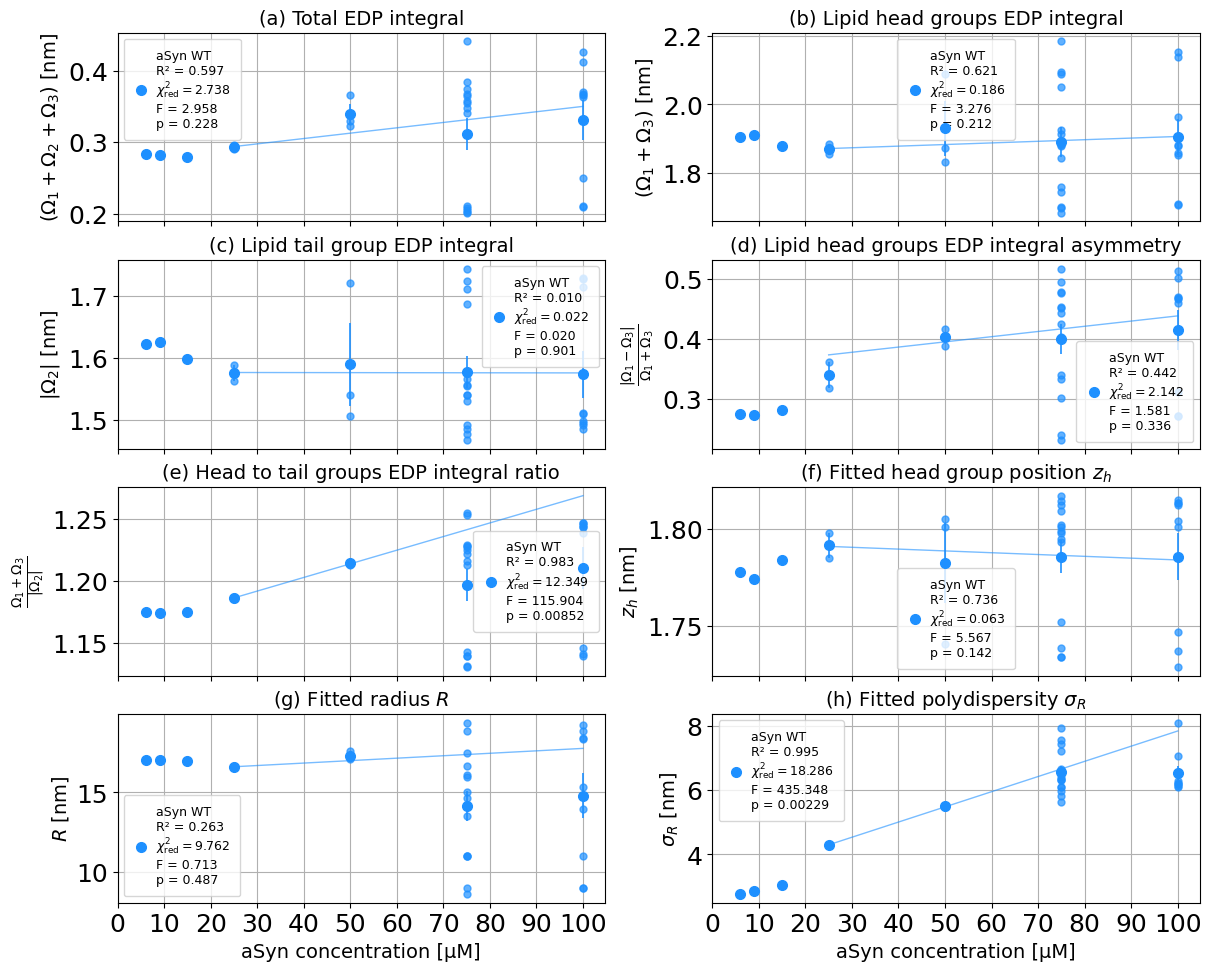

In [ ]:
### Plot PCPS + aSynWT statistics ===> linear fitting has to be adjusted!!!
DATASETS = {
    "WT": {
        "label": "aSyn WT",
        "color": "dodgerblue",
        "marker": "o",
        "best_fits": best_fits_PCPS_aSynWT,
        "sample_asyn": {
            "BII_S11": 0, #: "15 mM DOPC/DOPS (8/2)",

            "BIX_S15": 6, #: "15 mM DOPC/DOPS (8/2) + 6 μM aSynWT",
            "BIX_S16": 9, #: "15 mM DOPC/DOPS  (8/2) + 9 μM aSynWT",
            "BIX_S17": 15, #: "15 mM DOPC/DOPS (8/2) + 15 μM aSynWT",
            "BIX_S18": 25, #: "15 mM DOPC/DOPS (8/2) + 25 μM aSynWT",
            "BIX_S19": 50, #: "15 mM DOPC/DOPS (8/2) + 50 μM aSynWT",

            # "BVII_S4", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynWT", # bgr sub removed too much of the curve
            "BVII_S5": 100, #: "15 mM DOPC/DOPS (8/2) + 100 μM aSynWT",
            "BVII_S10": 75, #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynE61V",
            "BVII_S15": 75, #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynA124T",
            "BVII_S20": 75, #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynE46K",
        },
    },
}

from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import f
from matplotlib.lines import Line2D


# =============================================================================
# Configuration
# =============================================================================




# =============================================================================
# Metrics
# =============================================================================

METRICS = (
    "EDP_tot",
    "EDP_hg_tot",
    "EDP_tg",
    "EDP_hg_asym",
    "EDP_hg_tg",
    "z_h",
    "R",
    "sigma_R",
)


PLOT_INFO = [
    (
        "EDP_tot",
        "(a) Total EDP integral",
        r"$(\Omega_1 + \Omega_2 + \Omega_3)$ [nm]",
    ),
    (
        "EDP_hg_tot",
        "(b) Lipid head groups EDP integral",
        r"$(\Omega_1 + \Omega_3)$ [nm]",
    ),
    (
        "EDP_tg",
        "(c) Lipid tail group EDP integral",
        r"$|\Omega_2|$ [nm]",
    ),
    (
        "EDP_hg_asym",
        "(d) Lipid head groups EDP integral asymmetry",
        r"$\frac{|\Omega_1-\Omega_3|}{\Omega_1+\Omega_3}$",
    ),
    (
        "EDP_hg_tg",
        "(e) Head to tail groups EDP integral ratio",
        r"$\frac{\Omega_1+\Omega_3}{|\Omega_2|}$",
    ),
    (
        "z_h",
        "(f) Fitted head group position $z_h$",
        r"$z_h$ [nm]",
    ),
    (
        "R",
        "(g) Fitted radius $R$",
        r"$R$ [nm]",
    ),
    (
        "sigma_R",
        "(h) Fitted polydispersity $\sigma_R$",
        r"$\sigma_R$ [nm]",
    ),
]


# =============================================================================
# Helper functions
# =============================================================================

def linear(x, m, n):
    return m * x + n


def mean_and_sem(values):
    """
    Calculate ordinary arithmetic mean and SEM.
    """
    values = np.asarray(values, dtype=float)

    if values.size == 0:
        return np.nan, np.nan

    mean = np.mean(values)

    if values.size < 2:
        return mean, np.nan

    sem = np.std(values, ddof=1) / np.sqrt(values.size)

    return mean, sem


def collect_metrics(best_fits, sample_asyn):
    """
    Extract all individual fit configurations.

    No chi2 weighting is applied.
    """
    records = []

    for sample, asyn_conc in sample_asyn.items():

        if sample not in best_fits:
            continue

        fit_configs = best_fits[sample].get("ULV_spheric_asym_C4", {}).copy()
        # fit_configs.update(best_fits[sample].get("ULV_sph_asym_prot_layer", {}))

        for config_id, params in fit_configs.items():

            edp_params = params[2:8]

            (
                edp_tot,
                edp_hg_tot,
                edp_tg,
                edp_hg_asym,
                edp_hg_tg,
            ) = fit.EDP_analysis(edp_params)

            records.append({
                "sample": sample,
                "config": config_id,
                "aSyn": asyn_conc,

                "EDP_tot": edp_tot,
                "EDP_hg_tot": edp_hg_tot,
                "EDP_tg": abs(edp_tg),
                "EDP_hg_asym": edp_hg_asym,
                "EDP_hg_tg": edp_hg_tg,

                "R": params[0],
                "sigma_R": params[1],
                "z_h": params[7],
            })

    return records


def aggregate_by_concentration(records):
    """
    Group individual fits by aSyn concentration and calculate
    ordinary mean + SEM.
    """
    groups = defaultdict(list)

    for record in records:
        groups[record["aSyn"]].append(record)

    concentrations = np.array(
        sorted(groups.keys()),
        dtype=float,
    )

    means = {}
    sems = {}

    for metric in METRICS:

        metric_means = []
        metric_sems = []

        for concentration in concentrations:

            values = [
                record[metric]
                for record in groups[concentration]
            ]

            mean, sem = mean_and_sem(values)

            metric_means.append(mean)
            metric_sems.append(sem)

        means[metric] = np.asarray(metric_means)
        sems[metric] = np.asarray(metric_sems)

    return concentrations, means, sems


def make_legend_handle(color, marker, label):
    """
    Create a clean legend handle for one dataset.
    """
    return Line2D(
        [0],
        [0],
        linestyle="None",
        marker=marker,
        markersize=7,
        color=color,
        label=label,
    )


# =============================================================================
# Collect all data
# =============================================================================

all_data = {}

for dataset_name, dataset in DATASETS.items():

    records = collect_metrics(
        dataset["best_fits"],
        dataset["sample_asyn"],
    )

    if not records:
        print(
            f"Warning: no records found for {dataset_name}"
        )
        continue

    concentrations, means, sems = aggregate_by_concentration(
        records
    )

    all_data[dataset_name] = {
        "records": records,
        "style": dataset,

        # Individual points
        "aSyn_all": np.array(
            [record["aSyn"] for record in records]
        ),

        "data": {
            metric: np.array(
                [record[metric] for record in records]
            )
            for metric in METRICS
        },

        # Means and SEMs
        "aSyn_means": concentrations,
        "means": means,
        "sems": sems,
    }


# =============================================================================
# Plot
# =============================================================================

# plt.rcParams.update({
#     "font.family": "serif",
#     "mathtext.fontset": "dejavuserif",
# })

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(12, 9.6),
    sharex=True,
    constrained_layout=True,
)

axes = axes.flatten()


# Store statistics for optional later use
fit_statistics = {}


for ax, (metric, title, ylabel) in zip(
    axes,
    PLOT_INFO,
):

    fit_statistics[metric] = {}

    legend_handles = []

    for dataset_name, dataset in all_data.items():

        style = dataset["style"]
        color = style["color"]
        marker = style["marker"]
        label = style["label"]

        # =====================================================================
        # Individual fit configurations
        # =====================================================================

        ax.plot(
            dataset["aSyn_all"],
            dataset["data"][metric],

            linestyle="None",
            marker=marker,
            markersize=5,

            color=color,
            alpha=0.7,
        )

        # =====================================================================
        # Mean ± SEM
        # =====================================================================

        x_mean = dataset["aSyn_means"]
        y_mean = dataset["means"][metric]
        y_sem = dataset["sems"][metric]

        ax.errorbar(
            x_mean,
            y_mean,
            yerr=y_sem,

            linestyle="None",
            marker=marker,
            markersize=7,

            color=color,
            elinewidth=1.2,
            capsize=0,

            zorder=5,
        )

        # =====================================================================
        # Linear fit + statistics
        # =====================================================================

        statistics = BM29.calculate_linear_fit_statistics(
            x_mean,
            y_mean,
            y_sem,
        )

        if statistics is None:
            print(
                f"{dataset_name} – {metric}: "
                "not enough valid points for linear fit."
            )
            continue

        fit_statistics[metric][dataset_name] = statistics

        popt = statistics["popt"]
        perr = statistics["perr"]

        # ---------------------------------------------------------------------
        # Print results
        # ---------------------------------------------------------------------

        print(
            f"{dataset_name} – {metric}: "
            f"m = {popt[0]:.4g} ± {perr[0]:.4g}, "
            f"n = {popt[1]:.4g} ± {perr[1]:.4g}"
        )

        print(
            f"    R² = {statistics['r_squared_weighted']:.4f}, "
            f"χ²_red = {statistics['reduced_chi_squared']:.4f}, "
            f"F = {statistics['f_stat']:.4f}, "
            f"p = {statistics['p_value']:.4g}"
        )

        # ---------------------------------------------------------------------
        # Smooth fit line
        # ---------------------------------------------------------------------

        x_valid = statistics["x"]

        x_line = np.linspace(
            x_valid.min(),
            x_valid.max(),
            200,
        )

        ax.plot(
            x_line,
            linear(x_line, *popt),

            color=color,
            alpha=0.6,
            linewidth=1.0,
        )

        # ---------------------------------------------------------------------
        # Legend entry containing dataset + statistics
        # ---------------------------------------------------------------------

        legend_label = BM29.format_statistics_label(
            label,
            statistics,
        )

        legend_handles.append(
            make_legend_handle(
                color,
                marker,
                legend_label,
            )
        )

    # =========================================================================
    # Axis formatting
    # =========================================================================

    ax.set_title(
        title,
        fontsize=14,
    )

    ax.set_ylabel(
        ylabel,
        fontsize=14,
    )

    ax.grid(True)

    ax.set_xticks(
        np.arange(0, 105, 10)
    )

    # =========================================================================
    # Subplot-specific legend
    # =========================================================================

    if legend_handles:
        ax.legend(
            handles=legend_handles,
            loc="best",
            fontsize=9,
            frameon=True,
            handlelength=1.2,
            handletextpad=0.6,
            borderpad=0.8,
        )


# =============================================================================
# Common x-axis labels
# =============================================================================

for ax in axes[-2:]:
    ax.set_xlabel(
        "aSyn concentration [µM]",
        fontsize=14,
    )


# =============================================================================
# Save / show
# =============================================================================

# target_folder = Path("figures")
# fig.savefig(
#     target_folder / "EDP_metrics_spherical_WT_vs_A124T_stats.png",
#     dpi=600,
#     bbox_inches="tight",
# )

# fig.savefig(
#     target_folder / "EDP_metrics_spherical_WT_vs_A124T_stats.svg",
#     bbox_inches="tight",
# )

plt.show()

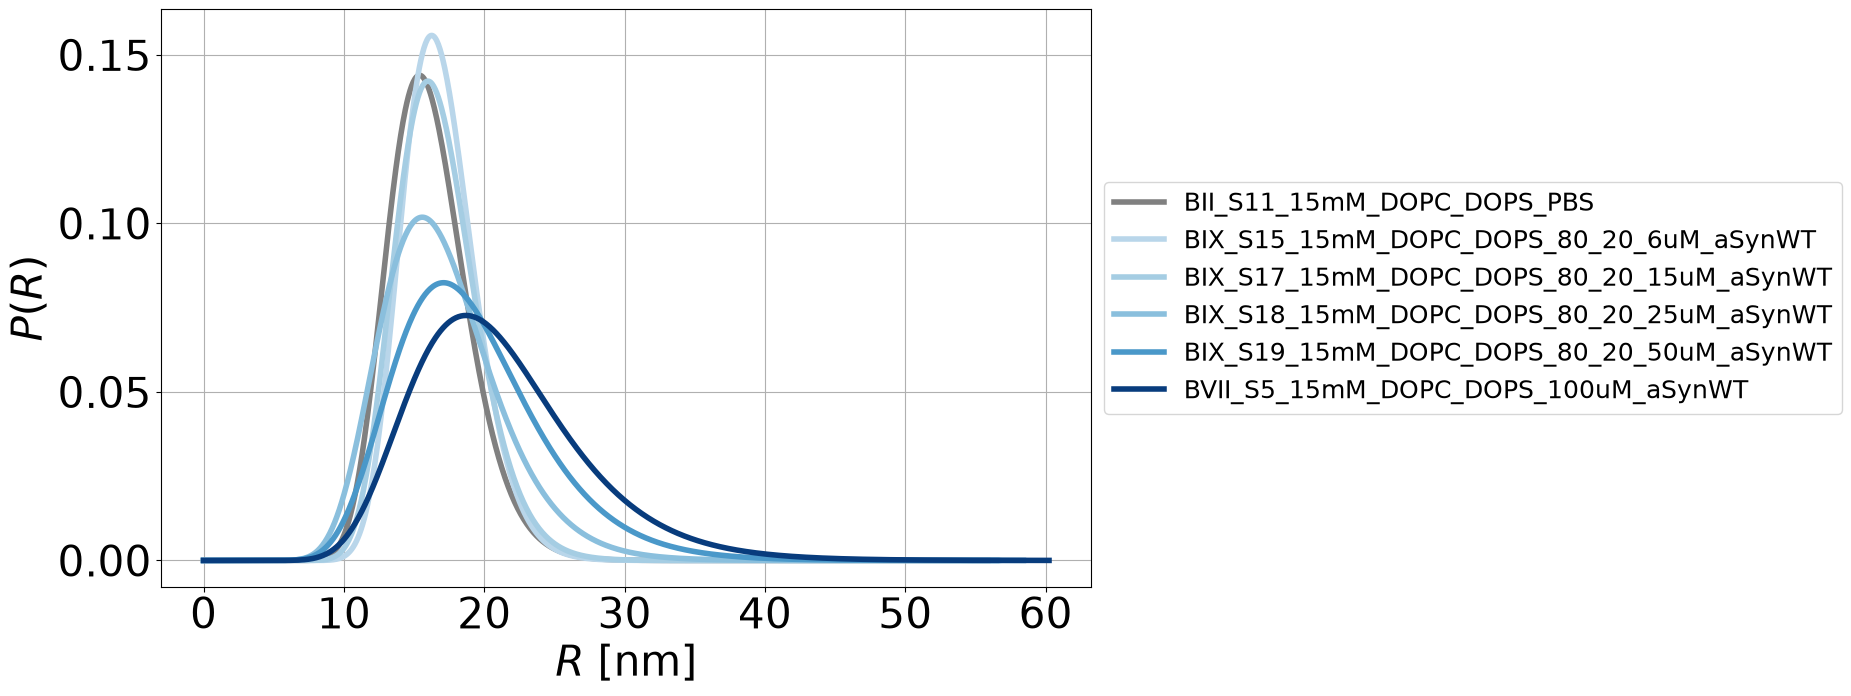

In [7]:
# plotting PCPS lognorm polydisp
PCPS = [
    "BII_S11", #: "15 mM DOPC/DOPS (8/2)",

    "BIX_S15", #: "15 mM DOPC/DOPS (8/2) + 6 μM aSynWT",
    # "BIX_S16", #: "15 mM DOPC/DOPS  (8/2) + 9 μM aSynWT",
    "BIX_S17", #: "15 mM DOPC/DOPS (8/2) + 15 μM aSynWT",
    "BIX_S18", #: "15 mM DOPC/DOPS (8/2) + 25 μM aSynWT",
    "BIX_S19", #: "15 mM DOPC/DOPS (8/2) + 50 μM aSynWT",

    # "BVII_S4", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynWT", # bgr sub removed too much of the curve
    "BVII_S5", #: "15 mM DOPC/DOPS (8/2) + 100 μM aSynWT",
    # "BVII_S10", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynE61V",
    # "BVII_S15", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynA124T",
    # "BVII_S20", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynE46K",

    # "BVII_S6", #: "3 mM DOPC/DOPS (8/2) + 100 μM aSynWT",
    # "BVII_S11", #: "3 mM DOPC/DOPS (8/2) + 100 μM aSynE61V",
    # "BVII_S16", #: "3 mM DOPC/DOPS (8/2) + 100 μM aSynA124T",
    # "BVII_S21", #: "3 mM DOPC/DOPS (8/2) + 100 μM aSynE46K",
]

who = PCPS
target_folder = Path("/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/Results_and_Figures/BVII_fit_results_Oct14")
g = BM29.plot_together_lognorm_polydisp(who)
# BM29.EDP_plot_together(who, "", fit_function="ULV_spheric_asym_C4_lognormal")
g.savefig(
    target_folder / f"BVII_PCPS_lognormal_polydisp_WT.png",
    dpi=700,
    bbox_inches="tight"
)

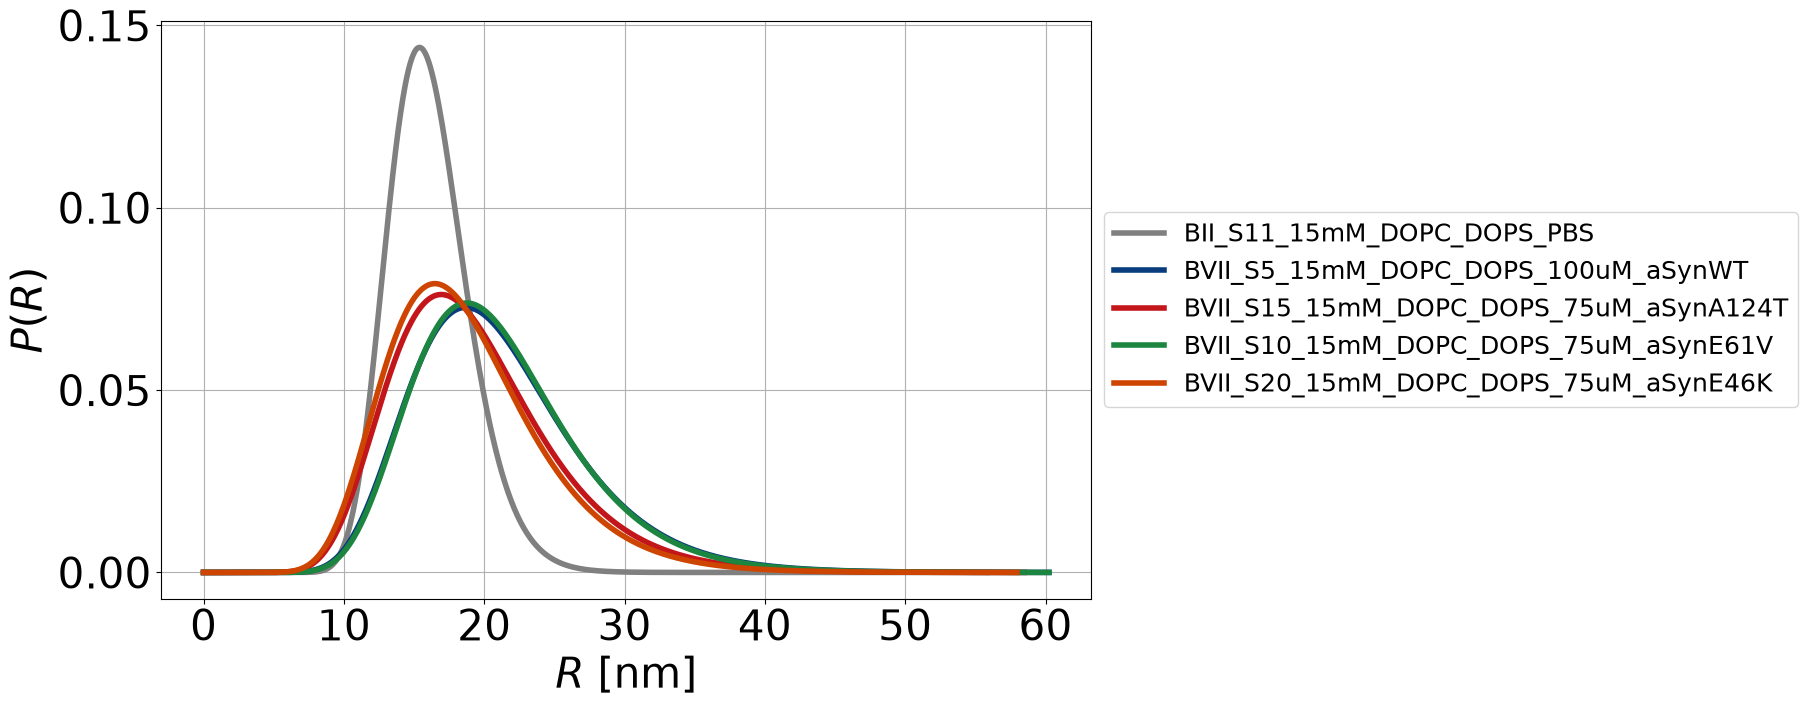

In [9]:
# PCPS lognorm polydisp VARIANTS
target_folder = Path("/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/Results_and_Figures/BVII_fit_results_Oct14")

who = [    "BII_S11"] + ["BVII_S5",] + ["BVII_S15"] + ["BVII_S10"] + ["BVII_S20"]

g = BM29.plot_together_lognorm_polydisp(who)
g.savefig(
    target_folder / f"PCPS_lognorm_polydisp_variants.png",
    dpi=400,
    bbox_inches="tight"
)

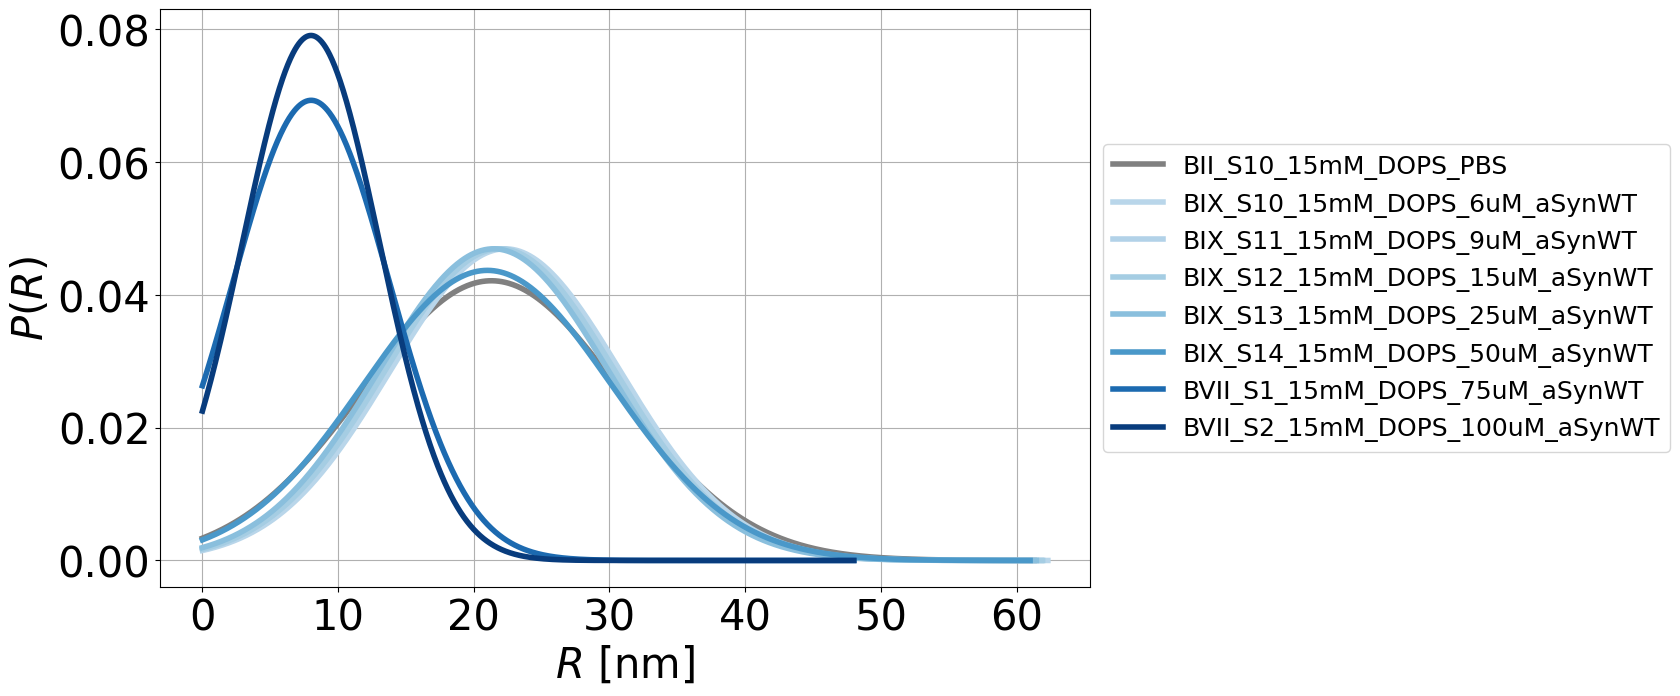

In [11]:
# plotting DOPS lognorm polydisp
DOPS = [
    "BII_S10", # : "15 mM DOPS",

    "BIX_S10", # : "15 mM DOPS + 6 μM aSynWT",
    "BIX_S11", # : "15 mM DOPS + 9 μM aSynWT",
    "BIX_S12", # : "15 mM DOPS + 15 μM aSynWT",
    "BIX_S13", # : "15 mM DOPS + 25 μM aSynWT",
    "BIX_S14", # : "15 mM DOPS + 50 μM aSynWT",

    "BVII_S1", # : "15 mM DOPS + 75 μM aSynWT",
    "BVII_S2", # : "15 mM DOPS + 100 μM aSynWT",
    # "BVII_S8", # : "15 mM DOPS + 75 μM aSynE61V",
    # "BVII_S13", # : "15 mM DOPS + 75 μM aSynA124T",
    # "BVII_S18", # : "15 mM DOPS + 75 μM aSynE46K",

    # "BVII_S3", # : "3 mM DOPS + 100 μM aSynWT",
    # "BVII_S9", # : "3 mM DOPS + 100 μM aSynE61V",
    # "BVII_S14", # : "3 mM DOPS + 100 μM aSynA124T",
    # "BVII_S19", # : "3 mM DOPS + 100 μM aSynE46K",
]

who = DOPS

g=BM29.plot_together_lognorm_polydisp(who, fit_function_name="ULV_spheric_asym_C4")
# BM29.EDP_plot_together(who, "", fit_function="ULV_spheric_asym_C4")
# target_folder = Path("C:/Users/rikoh/Documents/Physik Göttingen&Grenoble 2022-2026/8. SoSe 26/SHK Synaptische Proteine, Lipidmembranen SoSe 2026/Code/BM29_data_and_analysis/analysis_BM29_2026/Results_and_Figures/BVII_fit_results_Oct14")
# g.savefig(
#     target_folder / f"BVII_DOPS_lognormal_polydisp_WT.png",
#     dpi=200,
#     bbox_inches="tight"
# )
# f.savefig(
#     target_folder / f"BVII_DOPS_EDP_WT.png",
#     dpi=200,
#     bbox_inches="tight"
# )

['BIX_S12']
['BIX_S13']
['BIX_S14']
['BVII_S1']
['BVII_S2']


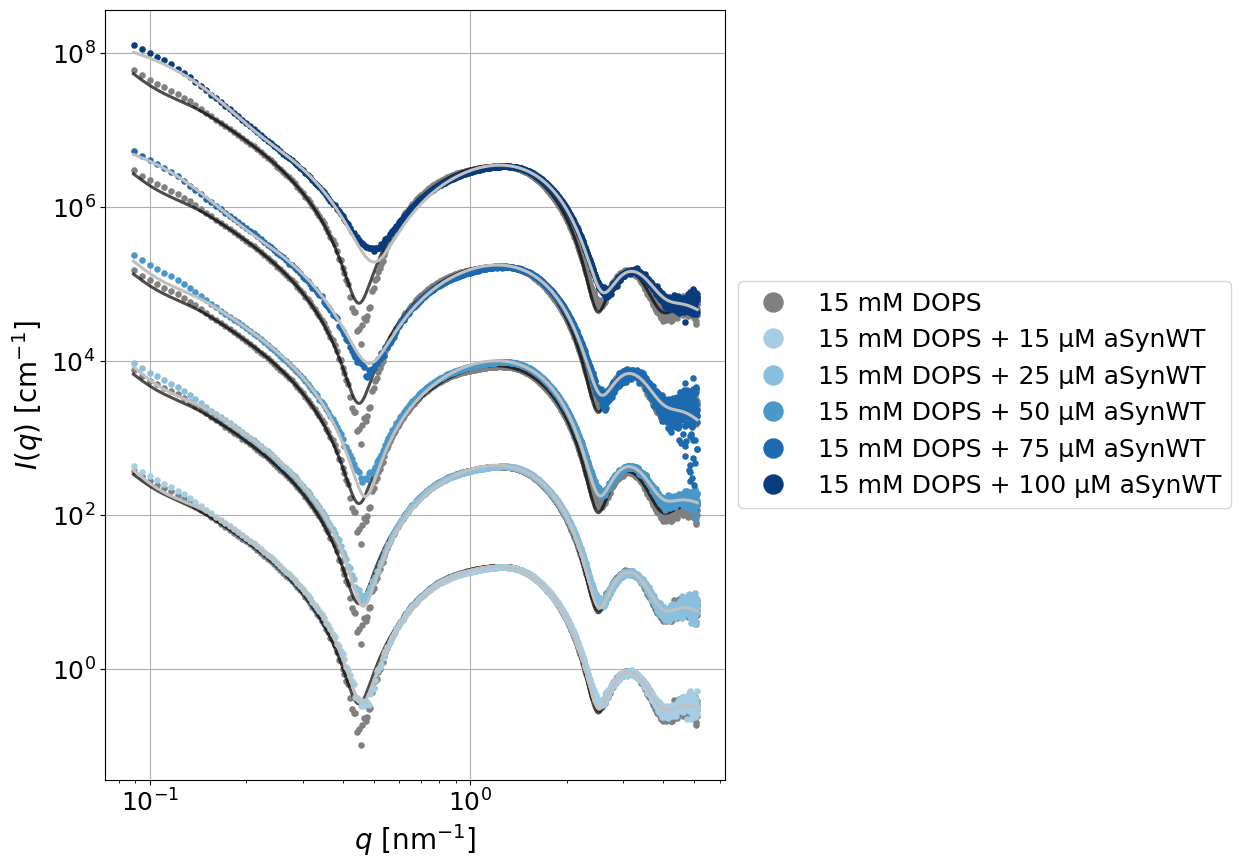

In [2]:
# SAXS curves + fits (BVII and BIX, DOPS) ULV_spheric_asym_C4

DOPS = [
    "BII_S10", # : "15 mM DOPS",

    # "BIX_S10", # : "15 mM DOPS + 6 μM aSynWT",
    # "BIX_S11", # : "15 mM DOPS + 9 μM aSynWT",
    "BIX_S12", # : "15 mM DOPS + 15 μM aSynWT",
    "BIX_S13", # : "15 mM DOPS + 25 μM aSynWT",
    "BIX_S14", # : "15 mM DOPS + 50 μM aSynWT",

    "BVII_S1", # : "15 mM DOPS + 75 μM aSynWT",
    "BVII_S2", # : "15 mM DOPS + 100 μM aSynWT",
    "BVII_S8", # : "15 mM DOPS + 75 μM aSynE61V",
    "BVII_S13", # : "15 mM DOPS + 75 μM aSynA124T",
    "BVII_S18", # : "15 mM DOPS + 75 μM aSynE46K",

    # "BVII_S3", # : "3 mM DOPS + 100 μM aSynWT",
    # "BVII_S9", # : "3 mM DOPS + 100 μM aSynE61V",
    # "BVII_S14", # : "3 mM DOPS + 100 μM aSynA124T",
    # "BVII_S19", # : "3 mM DOPS + 100 μM aSynE46K",
]
variant_dict = {
    "WT": [
        # "BIX_S10", # : "15 mM DOPS + 6 μM aSynWT",
        # "BIX_S11", # : "15 mM DOPS + 9 μM aSynWT",
        "BIX_S12", # : "15 mM DOPS + 15 μM aSynWT",
        "BIX_S13", # : "15 mM DOPS + 25 μM aSynWT",
        "BIX_S14", # : "15 mM DOPS + 50 μM aSynWT",
        "BVII_S1", # : "15 mM DOPS + 75 μM aSynWT",
        "BVII_S2", # : "15 mM DOPS + 100 μM aSynWT",
        ],
    "A124T": ["BVI_S9"],
    "E61V": ["BVI_S8"],
    "E46K": ["BVI_S10"],
}
shift_number = 20
from matplotlib import colormaps
from scipy.stats import lognorm
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
marker_standard = 3.7
lw_standard = 2.2
fit_color = "silver"
lv_color = "darkgrey"


# fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym_lognormal(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
def load_sample(sample):

    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)

    for dir_name in block_path.iterdir():

        if dir_name.name[:-13].endswith(sample):

            sub_dat_path = (
                dir_name
                / "avg_and_sub"
                / BM29.sample_dict[sample]
            )

            q, I, Ierr = np.loadtxt(
                sub_dat_path,
                unpack=True
            )

            mask = (q >= 0.085) & (q <= 5.1)

            return (
                q[mask],
                I[mask],
                Ierr[mask]
            )

def BVII_plot_together_DOPS(who, title, variant="WT"):

    plt.close("all")

    f = plt.figure(figsize=(8, 10))
    shift_factors = {
        6:     shift_number**(0),
        9:     shift_number**(1),
        15:    shift_number**(2),
        25.0:   shift_number**(3),
        50.0:   shift_number**(4),
        75.0:   shift_number**(5),
        100.0:  shift_number**(6),
    }
    c_min = 0
    c_max = 100
    if variant == "WT":
        colors = colormaps["Blues"]
    elif variant == "E61V":
        colors = colormaps["Greens"]
    elif variant == "E46K":
        colors = colormaps["Oranges"]
    elif variant == "A124T":
        colors = colormaps["Reds"]

    # fit_function_name = "ULV_spheric_asym_C4_lognormal"
    fit_function_name = "ULV_spheric_asym_C4"
    lv_label_added = False

    concentrations_to_plot = sorted(
        set(
            BM29.concentrations[sample]
            for sample in who
        )
    )

    for concentration in concentrations_to_plot[1:]:

        prot_samples = [sample for sample in who[1:] if sample in variant_dict[variant] and BM29.concentrations[sample] == concentration]
        print(prot_samples)
        prot_sample = prot_samples[0]
        lv_sample = "BII_S10" # : "15 mM DOPS"
        shift = shift_factors[concentration]

        # =====================================================
        # COLORS
        # =====================================================

        norm = (
            concentration - c_min
        ) / (
            c_max - c_min
        )
        # norm = LogNorm(vmin=1, vmax=100)


        # Avoid extremely pale colors
        norm = 0.25 + 0.70 * norm

        prot_color = colors(norm)

                # =====================================================
        # PURE LV
        # =====================================================

        q, I, Ierr = load_sample(lv_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                lv_sample
            ][fit_function_name][1]
        )

        # Apply EXACTLY THE SAME shift as WT and A124T
        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        # -----------------------------------------------------
        # Add pure LV to legend only once
        # -----------------------------------------------------

        if not lv_label_added:

            lv_label = BM29.nice_sample_names[lv_sample]
            lv_label_added = True

        else:

            lv_label = "_nolegend_"

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color="grey",
            markersize=marker_standard,
            label=lv_label
        )

        plt.plot(
            q,
            I_fit_shifted,
            color="black",
            label="_nolegend_",
            lw=lw_standard, #zorder=4
            alpha=0.7
        )

        # =====================================================
        # prot
        # =====================================================

        q, I, Ierr = load_sample(prot_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                prot_sample
            ][fit_function_name][1]
        )

        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color=prot_color,
            markersize=marker_standard,
            label=BM29.nice_sample_names[prot_sample]
        )

        plt.plot(
            q,
            I_fit_shifted,
            color=fit_color,
            label="_nolegend_",
            lw=lw_standard #, zorder=4
        )



    # =========================================================
    # Formatting
    # =========================================================

    plt.xscale("log")
    plt.yscale("log")

    # plt.title(title)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    plt.xlabel(r'$q\ [\mathrm{nm}^{-1}]$', fontsize=20)
    plt.ylabel(r'$I(q)\ [\mathrm{cm}^{-1}]$', fontsize=20)

    plt.grid()

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        alignment="left",
        markerscale=3.7
    )

    return f


# =============================================================
# Run
# =============================================================
variant = "WT"
who = ["BII_S10"] + variant_dict[variant]
f = BVII_plot_together_DOPS(
    who,
    "",
    variant=variant
)

target_folder = Path("C:/Users/rikoh/Documents/Physik Göttingen&Grenoble 2022-2026/8. SoSe 26/SHK Synaptische Proteine, Lipidmembranen SoSe 2026/Code/BM29_data_and_analysis/analysis_BM29_2026/Results_and_Figures/BVII_fit_results_Oct14"
)

# =============================================================
# Save
# =============================================================

f.savefig(
    target_folder / f"BVII_DOPS_curves_n_fits_lognormal_reduced_{variant}.png",
    dpi=700,
    bbox_inches="tight"
)
plt.show(f)

['BIX_S15']
['BIX_S17']
['BIX_S18']
['BIX_S19']
['BVII_S5']


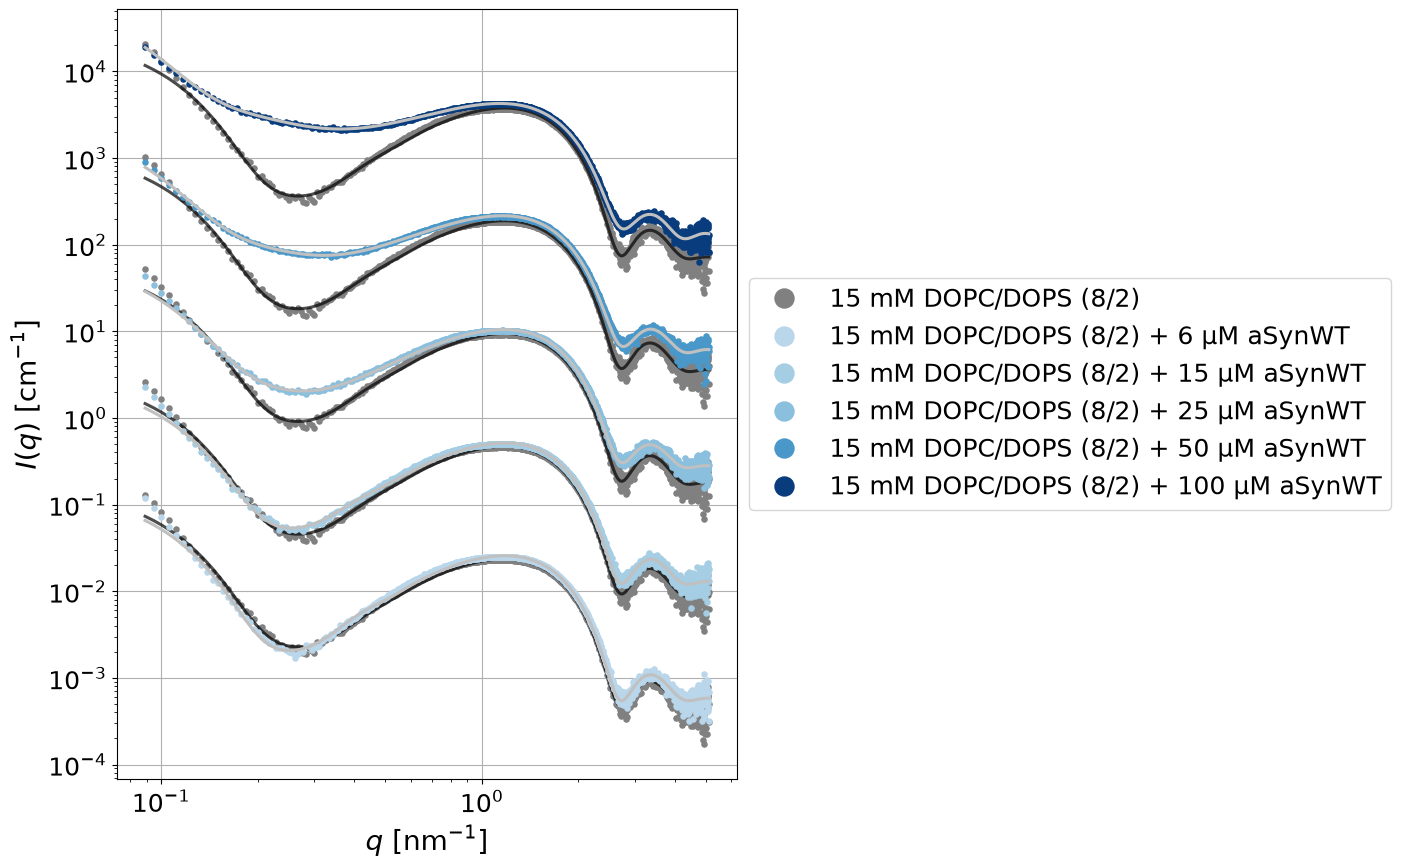

In [8]:
# SAXS curves + fits (BVII and BIX, DOPC/DOPS (8/2)) 

PCPS = [
    "BII_S11", #: "15 mM DOPC/DOPS (8/2)",

    "BIX_S15", #: "15 mM DOPC/DOPS (8/2) + 6 μM aSynWT",
    # "BIX_S16", #: "15 mM DOPC/DOPS  (8/2) + 9 μM aSynWT",
    "BIX_S17", #: "15 mM DOPC/DOPS (8/2) + 15 μM aSynWT",
    "BIX_S18", #: "15 mM DOPC/DOPS (8/2) + 25 μM aSynWT",
    "BIX_S19", #: "15 mM DOPC/DOPS (8/2) + 50 μM aSynWT",
    # "BVII_S4", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynWT", # bgr sub removed too much of the curve
    "BVII_S5", #: "15 mM DOPC/DOPS (8/2) + 100 μM aSynWT",
    # "BVII_S10", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynE61V",
    # "BVII_S15", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynA124T",
    # "BVII_S20", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynE46K",
]
variant_dict = {
    "WT": [
        "BIX_S15", #: "15 mM DOPC/DOPS (8/2) + 6 μM aSynWT",
        # "BIX_S16", #: "15 mM DOPC/DOPS  (8/2) + 9 μM aSynWT",
        "BIX_S17", #: "15 mM DOPC/DOPS (8/2) + 15 μM aSynWT",
        "BIX_S18", #: "15 mM DOPC/DOPS (8/2) + 25 μM aSynWT",
        "BIX_S19", #: "15 mM DOPC/DOPS (8/2) + 50 μM aSynWT",
        # "BVII_S4", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynWT", # bgr sub removed too much of the curve
        "BVII_S5", #: "15 mM DOPC/DOPS (8/2) + 100 μM aSynWT",
        ],
    "A124T": ["BVI_S9"],
    "E61V": ["BVI_S8"],
    "E46K": ["BVI_S10"],
}
shift_number = 20
from matplotlib import colormaps
from scipy.stats import lognorm
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
marker_standard = 3.7
lw_standard = 2.2
fit_color = "silver"
lv_color = "darkgrey"


fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym_lognormal(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
# fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
def load_sample(sample):

    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)

    for dir_name in block_path.iterdir():

        if dir_name.name[:-13].endswith(sample):

            sub_dat_path = (
                dir_name
                / "avg_and_sub"
                / BM29.sample_dict[sample]
            )

            q, I, Ierr = np.loadtxt(
                sub_dat_path,
                unpack=True
            )

            mask = (q >= 0.085) & (q <= 5.1)

            return (
                q[mask],
                I[mask],
                Ierr[mask]
            )

def BVII_plot_together_PCPS(who, title, variant="WT"):

    plt.close("all")

    f = plt.figure(figsize=(8, 10))
    shift_factors = {
        6:     shift_number**(0),
        # 9:     shift_number**(1),
        15:    shift_number**(1),
        25.0:   shift_number**(2),
        50.0:   shift_number**(3),
        # 75.0:   shift_number**(5),
        100.0:  shift_number**(4),
    }
    c_min = 0
    c_max = 100
    if variant == "WT":
        colors = colormaps["Blues"]
    elif variant == "E61V":
        colors = colormaps["Greens"]
    elif variant == "E46K":
        colors = colormaps["Oranges"]
    elif variant == "A124T":
        colors = colormaps["Reds"]

    fit_function_name = "ULV_spheric_asym_C4_lognormal"
    # fit_function_name = "ULV_spheric_asym_C4"
    lv_label_added = False

    concentrations_to_plot = sorted(
        set(
            BM29.concentrations[sample]
            for sample in who
        )
    )

    for concentration in concentrations_to_plot[1:]:

        prot_samples = [sample for sample in who[1:] if sample in variant_dict[variant] and BM29.concentrations[sample] == concentration]
        print(prot_samples)
        prot_sample = prot_samples[0]
        lv_sample = "BII_S11" 
        shift = shift_factors[concentration]

        # =====================================================
        # COLORS
        # =====================================================

        norm = (
            concentration - c_min
        ) / (
            c_max - c_min
        )
        # norm = LogNorm(vmin=1, vmax=100)


        # Avoid extremely pale colors
        norm = 0.25 + 0.70 * norm

        prot_color = colors(norm)

                # =====================================================
        # PURE LV
        # =====================================================

        q, I, Ierr = load_sample(lv_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                lv_sample
            ][fit_function_name][1]
        )

        # Apply EXACTLY THE SAME shift as WT and A124T
        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        # -----------------------------------------------------
        # Add pure LV to legend only once
        # -----------------------------------------------------

        if not lv_label_added:

            lv_label = BM29.nice_sample_names[lv_sample]
            lv_label_added = True

        else:

            lv_label = "_nolegend_"

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color="grey",
            markersize=marker_standard,
            label=lv_label
        )

        plt.plot(
            q,
            I_fit_shifted,
            color="black",
            label="_nolegend_",
            lw=lw_standard, #zorder=4
            alpha=0.7
        )

        # =====================================================
        # prot
        # =====================================================

        q, I, Ierr = load_sample(prot_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                prot_sample
            ][fit_function_name][1]
        )

        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color=prot_color,
            markersize=marker_standard,
            label=BM29.nice_sample_names[prot_sample]
        )

        plt.plot(
            q,
            I_fit_shifted,
            color=fit_color,
            label="_nolegend_",
            lw=lw_standard #, zorder=4
        )



    # =========================================================
    # Formatting
    # =========================================================

    plt.xscale("log")
    plt.yscale("log")

    # plt.title(title)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    plt.xlabel(r'$q\ [\mathrm{nm}^{-1}]$', fontsize=20)
    plt.ylabel(r'$I(q)\ [\mathrm{cm}^{-1}]$', fontsize=20)

    plt.grid()

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        alignment="left",
        markerscale=3.7
    )

    return f


# =============================================================
# Run
# =============================================================
variant = "WT"
who = ["BII_S11"] + variant_dict[variant]
f = BVII_plot_together_PCPS(
    who,
    "",
    variant=variant
)

target_folder = Path("/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/Results_and_Figures/BVII_fit_results_Oct14")

# =============================================================
# Save
# =============================================================

f.savefig(
    target_folder / f"BVII_PCPS_curves_n_fits_lognormal_{variant}.png",
    dpi=700,
    bbox_inches="tight"
)
plt.show(f)

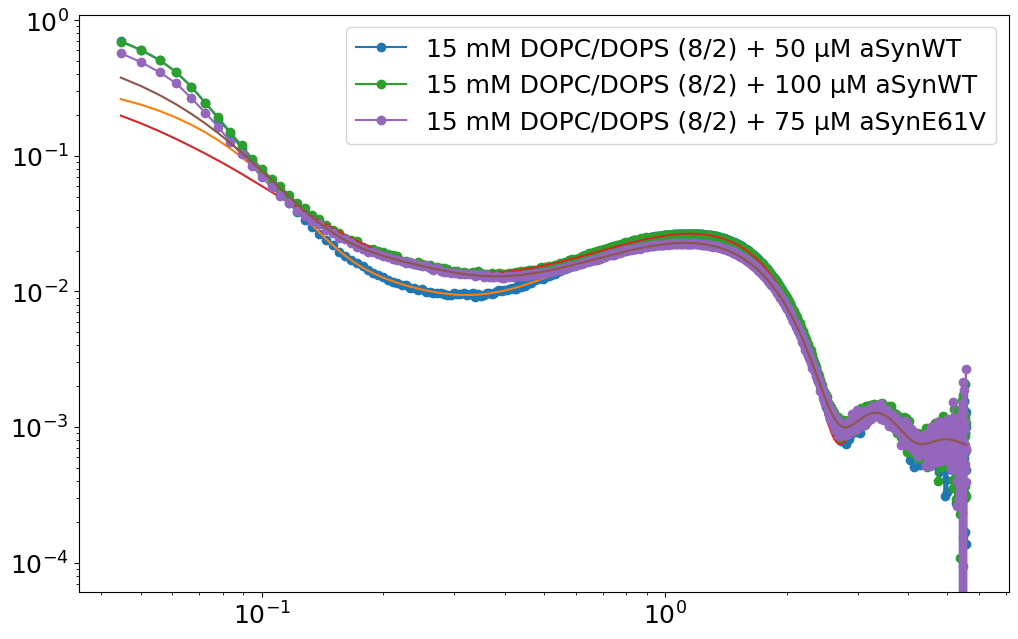

In [14]:
    # "BIX_S19", #: "15 mM DOPC/DOPS (8/2) + 50 μM aSynWT",
    # "BVII_S5", #: "15 mM DOPC/DOPS (8/2) + 100 μM aSynWT",
    # # "BVII_S10", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynE61V",
    # # "BVII_S15", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynA124T",
    # # "BVII_S20", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynE46K",
plt.figure(figsize=(12,7.5))
samples = ["BIX_S19", "BVII_S5", "BVII_S10"]
for sample in samples:
    # sample = "BVII_S10"
    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)
    dir_names = [x.name for x in block_path.iterdir()]
    for dir_name in dir_names:
        if dir_name[:-13].endswith(sample):
            sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
            q, I, Ierr_Poisson = np.loadtxt(sub_dat_path, unpack=True)

    fit_function_name = "ULV_spheric_asym_C4_lognormal"
    fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym_lognormal(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)

    plt.loglog(q, I, marker='o', ls=None, label=BM29.nice_sample_names[sample])
    I_fit = fit_function(q, *BM29.best_fits[sample][fit_function_name][1])
    plt.loglog(q, I_fit)
    plt.legend()

['BVI_S14']
['BVI_S19']
['BVI_S18']
['BVI_S20']


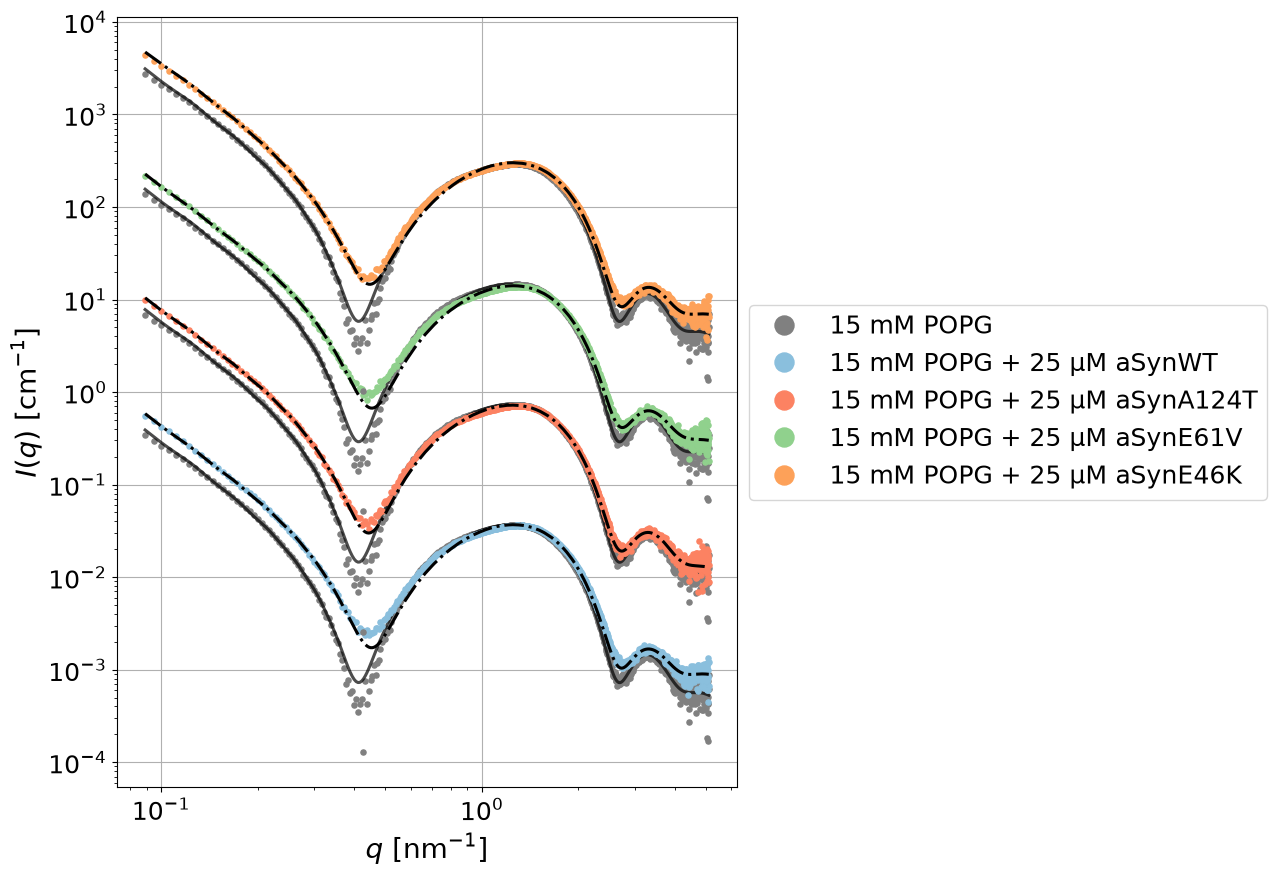

In [8]:
# SAXS curves + fits (POPG, variants)
variant_dict = {
    "WT": [
        # "BVI_S11",
        # "BVI_S12",
        #    "BVI_S13",
           "BVI_S14",
        #    "BVI_S15",
        #    "BVI_S16",
        #    "BVI_S17"
        ],
    "A124T": ["BVI_S19"],
    "E61V": ["BVI_S18"],
    "E46K": ["BVI_S20"],
}
shift_number = 20
from matplotlib import colormaps
from scipy.stats import lognorm
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
marker_standard = 3.7
lw_standard = 2.2
fit_color = "black"
lv_color = "darkgrey"


fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym_lognormal(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
def load_sample(sample):

    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)

    for dir_name in block_path.iterdir():

        if dir_name.name[:-13].endswith(sample):

            sub_dat_path = (
                dir_name
                / "avg_and_sub"
                / BM29.sample_dict[sample]
            )

            q, I, Ierr = np.loadtxt(
                sub_dat_path,
                unpack=True
            )

            mask = (q >= 0.085) & (q <= 5.1)

            return (
                q[mask],
                I[mask],
                Ierr[mask]
            )

def BVI_plot_together(who):

    plt.close("all")

    f = plt.figure(figsize=(8, 10))
    shift_factors = {
        "WT":     shift_number**(0),
        "A124T":     shift_number**(1),
        "E61V":    shift_number**(2),
        "E46K":   shift_number**(3),
    }
    c_min = 0
    c_max = 100
    fit_function_name = "ULV_spheric_asym_C4_lognormal"
    lv_label_added = False

    for variant in variant_dict.keys():
        if variant == "WT":
            colors = colormaps["Blues"]
        elif variant == "E61V":
            colors = colormaps["Greens"]
        elif variant == "E46K":
            colors = colormaps["Oranges"]
        elif variant == "A124T":
            colors = colormaps["Reds"]

        prot_samples = [sample for sample in who[1:] if sample in variant_dict[variant]]
        print(prot_samples)
        prot_sample = prot_samples[0]
        lv_sample = "BIX_S1"
        shift = shift_factors[variant]

        # =====================================================
        # COLORS
        # =====================================================

        norm = (
            BM29.concentrations[prot_sample] - c_min
        ) / (
            c_max - c_min
        )
        # norm = LogNorm(vmin=1, vmax=100)


        # Avoid extremely pale colors
        norm = 0.25 + 0.70 * norm

        prot_color = colors(norm)

                # =====================================================
        # PURE LV
        # =====================================================

        q, I, Ierr = load_sample(lv_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                lv_sample
            ][fit_function_name][1]
        )

        # Apply EXACTLY THE SAME shift as WT and A124T
        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        # -----------------------------------------------------
        # Add pure LV to legend only once
        # -----------------------------------------------------

        if not lv_label_added:

            lv_label = BM29.nice_sample_names[lv_sample]
            lv_label_added = True

        else:

            lv_label = "_nolegend_"

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color="grey",
            markersize=marker_standard,
            label=lv_label
        )

        plt.plot(
            q,
            I_fit_shifted,
            color="black",
            label="_nolegend_",
            lw=lw_standard, #zorder=4
            alpha=0.7
        )

        # =====================================================
        # prot
        # =====================================================

        q, I, Ierr = load_sample(prot_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                prot_sample
            ][fit_function_name][1]
        )

        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color=prot_color,
            markersize=marker_standard,
            label=BM29.nice_sample_names[prot_sample]
        )

        plt.plot(
            q,
            I_fit_shifted,
            color=fit_color,
            label="_nolegend_",
            lw=lw_standard, #, zorder=4
            ls="-.",
        )



    # =========================================================
    # Formatting
    # =========================================================

    plt.xscale("log")
    plt.yscale("log")

    # plt.title(title)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    plt.xlabel(r'$q\ [\mathrm{nm}^{-1}]$', fontsize=20)
    plt.ylabel(r'$I(q)\ [\mathrm{cm}^{-1}]$', fontsize=20)

    plt.grid()

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        alignment="left",
        markerscale=3.7
    )

    return f


# =============================================================
# Run
# =============================================================
who = ["BIX_S1"] + ["BVI_S14",] + ["BVI_S19"] + ["BVI_S18"] + ["BVI_S20"]
f = BVI_plot_together(
    who,
)

target_folder = Path("/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/Results_and_Figures/BVI_fit_results_Oct06")

# =============================================================
# Save
# =============================================================
f.savefig(
    target_folder / f"POPG_curves_n_fits_variants.png",
    dpi=500,
    bbox_inches="tight"
)
plt.show(f)

['BVII_S5']
['BVII_S15']
['BVII_S10']
['BVII_S20']


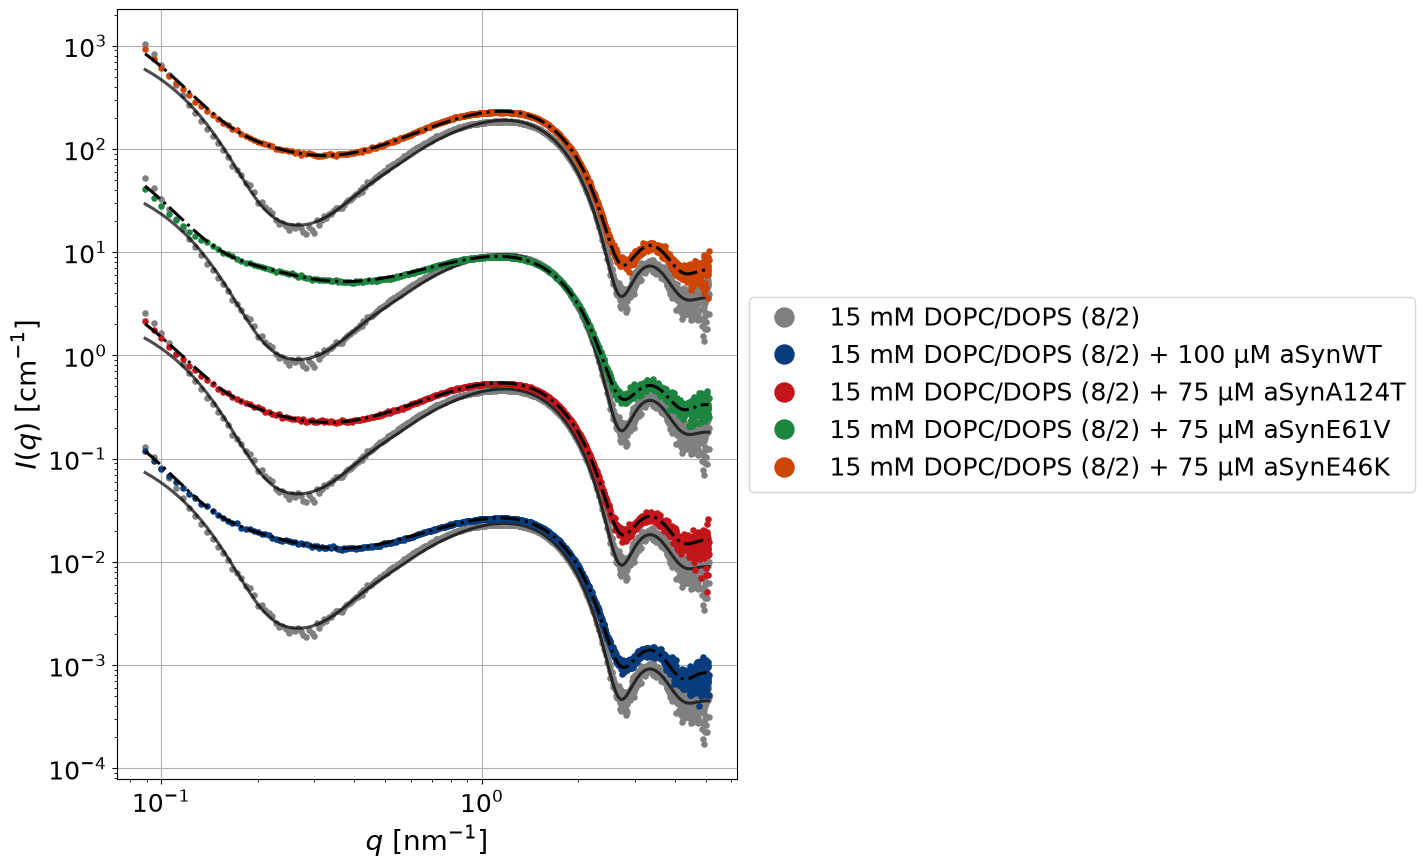

In [7]:
# SAXS curves + fits (PCPS, variants)
variant_dict = {
    "WT": [
        "BIX_S15", #: "15 mM DOPC/DOPS (8/2) + 6 μM aSynWT",
        # "BIX_S16", #: "15 mM DOPC/DOPS  (8/2) + 9 μM aSynWT",
        "BIX_S17", #: "15 mM DOPC/DOPS (8/2) + 15 μM aSynWT",
        "BIX_S18", #: "15 mM DOPC/DOPS (8/2) + 25 μM aSynWT",
        "BIX_S19", #: "15 mM DOPC/DOPS (8/2) + 50 μM aSynWT",
        # "BVII_S4", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynWT", # bgr sub removed too much of the curve
        "BVII_S5", #: "15 mM DOPC/DOPS (8/2) + 100 μM aSynWT",
        ],
    "A124T": ["BVII_S15"],
    "E61V": ["BVII_S10"],
    "E46K": ["BVII_S20"],
}
shift_number = 20
from matplotlib import colormaps
from scipy.stats import lognorm
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
marker_standard = 3.7
lw_standard = 2.2
fit_color = "black"
lv_color = "darkgrey"


fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym_lognormal(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
def load_sample(sample):

    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)

    for dir_name in block_path.iterdir():

        if dir_name.name[:-13].endswith(sample):

            sub_dat_path = (
                dir_name
                / "avg_and_sub"
                / BM29.sample_dict[sample]
            )

            q, I, Ierr = np.loadtxt(
                sub_dat_path,
                unpack=True
            )

            mask = (q >= 0.085) & (q <= 5.1)

            return (
                q[mask],
                I[mask],
                Ierr[mask]
            )

def BVI_plot_together(who):

    plt.close("all")

    f = plt.figure(figsize=(8, 10))
    shift_factors = {
        "WT":     shift_number**(0),
        "A124T":     shift_number**(1),
        "E61V":    shift_number**(2),
        "E46K":   shift_number**(3),
    }
    c_min = 0
    c_max = 100
    fit_function_name = "ULV_spheric_asym_C4_lognormal"
    lv_label_added = False

    for variant in variant_dict.keys():
        if variant == "WT":
            colors = colormaps["Blues"]
        elif variant == "E61V":
            colors = colormaps["Greens"]
        elif variant == "E46K":
            colors = colormaps["Oranges"]
        elif variant == "A124T":
            colors = colormaps["Reds"]

        prot_samples = [sample for sample in who[1:] if sample in variant_dict[variant]]
        print(prot_samples)
        prot_sample = prot_samples[0]
        lv_sample = "BII_S11"
        shift = shift_factors[variant]

        # =====================================================
        # COLORS
        # =====================================================

        norm = (
            BM29.concentrations[prot_sample] - c_min
        ) / (
            c_max - c_min
        )
        # norm = LogNorm(vmin=1, vmax=100)


        # Avoid extremely pale colors
        norm = 0.25 + 0.70 * norm

        prot_color = colors(norm)

                # =====================================================
        # PURE LV
        # =====================================================

        q, I, Ierr = load_sample(lv_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                lv_sample
            ][fit_function_name][1]
        )

        # Apply EXACTLY THE SAME shift as WT and A124T
        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        # -----------------------------------------------------
        # Add pure LV to legend only once
        # -----------------------------------------------------

        if not lv_label_added:

            lv_label = BM29.nice_sample_names[lv_sample]
            lv_label_added = True

        else:

            lv_label = "_nolegend_"

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color="grey",
            markersize=marker_standard,
            label=lv_label
        )

        plt.plot(
            q,
            I_fit_shifted,
            color="black",
            label="_nolegend_",
            lw=lw_standard, #zorder=4
            alpha=0.7
        )

        # =====================================================
        # prot
        # =====================================================

        q, I, Ierr = load_sample(prot_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                prot_sample
            ][fit_function_name][1]
        )

        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color=prot_color,
            markersize=marker_standard,
            label=BM29.nice_sample_names[prot_sample]
        )

        plt.plot(
            q,
            I_fit_shifted,
            color=fit_color,
            label="_nolegend_",
            lw=lw_standard, #, zorder=4
            ls="-.",
        )



    # =========================================================
    # Formatting
    # =========================================================

    plt.xscale("log")
    plt.yscale("log")

    # plt.title(title)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    plt.xlabel(r'$q\ [\mathrm{nm}^{-1}]$', fontsize=20)
    plt.ylabel(r'$I(q)\ [\mathrm{cm}^{-1}]$', fontsize=20)

    plt.grid()

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        alignment="left",
        markerscale=3.7
    )

    return f


# =============================================================
# Run
# =============================================================
# "BIX_S19", #: "15 mM DOPC/DOPS (8/2) + 50 μM aSynWT",
# # "BVII_S4", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynWT", # bgr sub removed too much of the curve
# "BVII_S5", #: "15 mM DOPC/DOPS (8/2) + 100 μM aSynWT",

who = [" "] + ["BVII_S5",] + ["BVII_S15"] + ["BVII_S10"] + ["BVII_S20"]
f = BVI_plot_together(
    who,
)

target_folder = Path("/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/Results_and_Figures/BVII_fit_results_Oct14")

# =============================================================
# Save
# =============================================================
f.savefig(
    target_folder / f"PCPS_curves_n_fits_variants.png",
    dpi=500,
    bbox_inches="tight"
)
plt.show(f)